# 04. Признаки: что модель будет знать о прошлом объекта

**Что делаем.** Модель должна в 00:00 каждых суток сказать для каждого объекта коллектора, насколько вероятен
в ближайшие 24 часа отказ оборудования, пожар, подтопление или любой инцидент, а для редких классов (газ, потеря
связи, неисправность охраны) достаточно фоновой частоты. Для этого ей нужны признаки:
числа, которые описывают состояние объекта к моменту прогноза. Здесь мы строим такие признаки из журнала событий
СМВУ, для каждой группы проверяем, есть ли в ней сигнал, отбираем рабочий набор и собираем итоговую матрицу
«объект × сутки» для обучения. Саму модель здесь не обучаем: единственный прогноз в этом ноутбуке – простейший
частотный, нижняя планка, которую модель обязана обойти.

**Главное правило – никакого знания о будущем.** Признак на сутки `D` вычисляется только из того, что было
известно до `D 00:00`. Если хоть один признак «подсмотрит» события самих суток `D`, модель научится узнавать
инцидент по его же следам и покажет на истории блестящую точность, которой в работе не будет. Поэтому правило
закладываем в сами функции расчета, а в разделе 9 проверяем тремя независимыми способами.

**Как устроен ноутбук.**

0. Задача, данные и способ оценки признака
1. Горизонт памяти: какие окна брать
2. История объекта по классам инцидентов, часы с последнего эпизода
3. Каналы: сколько датчиков сбоит и как долго
4. Потеря связи и активность каналов
5. Телеметрия: газ и температура
6. Контекст работ, календарь, производственный календарь и плановые работы АКМ
7. Подтопление: насосы
8. Эпохи, вся система, соседи, постоянные свойства объекта
9. Проверка утечки
10. Отбор признаков и каталог
11. Итоговая матрица и частотный прогноз
12. Итоги

Код построения признаков (строители групп `build_*`, сборка `build_all`, обрезка данных на полночь `cut` и их
вспомогательные функции) лежит в пакете проекта, в модуле `annanas.inference.features`: тем же кодом сервис
считает прогноз на сутки. Здесь мы вызываем его группа за группой и перед каждым вызовом объясняем, что строит
группа и почему. Все времена московские.

In [1]:
import glob
import re
import time

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
from IPython.display import display
from pyspark.sql import functions as F

from annanas import aggregates as agg
from annanas import calendar_ru as cal
from annanas import episodes as ep
from annanas import features as fe
from annanas import maintenance as mt
from annanas.inference import features as fi
from annanas.paths import EDA_DIR, EVENTS_DIR, PROCESSED_DIR
from annanas.spark import get_spark

spark = get_spark("04_features")
spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "true")  # быстрый toPandas
spark.conf.set("spark.sql.shuffle.partitions", "400")  # группировка по сотням миллионов записей журнала
FEAT_DIR = PROCESSED_DIR / "features"
FEAT_DIR.mkdir(parents=True, exist_ok=True)
KEY = fe.KEY

pd.set_option("display.max_rows", 500)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 240)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}".replace(",", " "))

# Оформление графиков: фиксированная категориальная палитра, тонкие линии, приглушенные оси
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
GREY, INK, INK2 = "#9a9994", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (12, 4.5), "figure.dpi": 110, "figure.constrained_layout.use": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "legend.frameon": False, "lines.linewidth": 1.5, "axes.prop_cycle": plt.cycler(color=PALETTE),
})
TARGET_COLOR = {"отказ": PALETTE[0], "пожар": PALETTE[1], "подтопление": PALETTE[2], "любой_инцидент": PALETTE[3]}


def n(v) -> str:
    """Число с пробелом-разделителем тысяч."""
    return f"{v:,.0f}".replace(",", " ")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/09/26 03:55:40 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/09/26 03:55:40 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in standalone/kubernetes and LOCAL_DIRS in YARN).


## 0. Задача, данные и способ оценки признака

### 0.1 Что прогнозируем
Целевая таблица – сетка «объект × сутки» с 2019-01-01 по 2026-06-30. В строке суток `D` цель класса равна 1,
если в окне `[D 00:00, D + 24 ч)` на объекте начался эпизод этого класса длительностью не меньше минуты (потеря
связи – не меньше 10 минут). Столбец `маска` помечает сутки, которые нельзя использовать ни для обучения, ни для
оценки. Это известные периоды сбоев (переход на новую СМВУ с 2021-04-21, сбой июля 2021, обрыв апреля 2024,
отсутствие данных 2026-06-01), две маски связи объекта, которые решаются только по записям строго до `D 00:00`,
то есть так же, как их увидел бы сервис в полночь, и маска плановых работ:

- «объект не подключен» – у объекта до суток `D` еще не было ни одной записи;
- «объект не на связи» – объект обычно пишет постоянно (медиана больше 200 записей в сутки за 30 суток), но все
  сутки `D − 1` молчал;
- «плановые работы АКМ» – сутки окна планово-предупредительных работ (ППР) аппаратуры контроля метана с запасом
  ±3 суток. Раз в год датчики метана объекта снимают на поверку, возвращают и сдают, проверяя тестовым газом, и
  журнал в эти дни показывает «Обнаружен газ» сразу на большинстве газовых каналов объекта, а также отказы и
  переключения оборудования при приемке. Это обслуживание, а не инциденты. Окна 2026 года взяты из графика ППР
  заказчика, окна прошлых лет восстановлены по журналу: кластеры дней, когда тестовый газ виден на половине
  газовых каналов объекта в рабочее время. Таблица окон лежит в `datasets/processed/maintenance/ppr_windows.parquet`.

Тихие сутки подключенного объекта, который пишет редко (например, только дискретные датчики), не маскируются: для
него отсутствие записей – обычный день без событий, то есть отрицательный пример. `выборка` делит время: обучение
2019-2024, валидация 2025, тест январь-июнь 2026.

Модель будет строиться для четырех целей: отказ, пожар, подтопление и любой инцидент (отказ, подтопление, пожар,
газ или потеря связи). Газ и потеря связи слишком редки для отдельной модели, для них достаточно частотной оценки.
Неисправность охраны («Состояние охраны: Много неисправных устройств») – отдельный класс: он не указывает на
конкретное оборудование и плохо прогнозируется, поэтому в отказ и в любой инцидент не входит, а для него тоже
считаем частотную оценку. Проникновение – не прогноз, а сигнал охраны. Посмотрим, сколько положительных примеров у
каждой цели на рабочих (незамаскированных) строках.

In [2]:
target = agg.read_vitrine(PROCESSED_DIR / "target.parquet").drop(columns=["пикеты"])  # пикеты – локация цели, не признак
target["день"] = pd.to_datetime(target["день"])
grid = target  # сетка признаков совпадает с целевой таблицей: те же строки в том же порядке
TARGETS = ["отказ", "подтопление", "пожар", "газ", "потеря_связи", "проникновение", "неисправность_охраны",
           "любой_инцидент"]
MODEL_TARGETS = ["отказ", "пожар", "подтопление", "любой_инцидент"]
DAYS = pd.date_range(grid["день"].min(), grid["день"].max(), freq="D")
OBJECTS = np.sort(grid["ид_объект"].unique())
print(f"строк: {n(len(grid))}, объектов: {len(OBJECTS)}, суток: {n(len(DAYS))}, "
      f"сетка полная: {len(grid) == len(OBJECTS) * len(DAYS)}")
OK = grid["маска"].isna().to_numpy()
SPLIT = grid["выборка"].to_numpy()
TRAIN, VALID, TEST = OK & (SPLIT == "обучение"), OK & (SPLIT == "валидация"), OK & (SPLIT == "тест")
LATE = VALID | TEST
AFTER = (grid["эпоха_флага"] == "после смены разметки").to_numpy()
Y = {t: grid[f"цель_{t}"].to_numpy() for t in TARGETS}

rates = pd.DataFrame({name: {t: Y[t][m].mean() for t in TARGETS} for name, m in
                      [("обучение", TRAIN), ("валидация", VALID), ("тест", TEST)]})
rates["положительных_в_обучении"] = [int(Y[t][TRAIN].sum()) for t in TARGETS]
display(rates.style.format({c: "{:.2%}" for c in ["обучение", "валидация", "тест"]}))
print(f"рабочих строк без масок: обучение {n(TRAIN.sum())}, валидация {n(VALID.sum())}, тест {n(TEST.sum())}; "
      f"с маской: {n((~OK).sum())} ({(~OK).mean():.0%})")
display(grid.groupby(["выборка", "эпоха_флага"], sort=False).size().rename("строк").to_frame())
display(grid["маска"].fillna("без маски").value_counts().rename("строк").to_frame().T)

строк: 213 564, объектов: 78, суток: 2 738, сетка полная: True


,обучение,валидация,тест,положительных_в_обучении
отказ,2.91%,3.06%,4.26%,3780
подтопление,0.79%,0.43%,0.65%,1027
пожар,1.44%,1.63%,2.01%,1872
газ,0.14%,0.06%,0.11%,177
потеря_связи,0.28%,0.09%,0.24%,364
проникновение,10.57%,8.52%,8.97%,13749
неисправность_охраны,2.04%,2.37%,1.73%,2656
любой_инцидент,4.87%,4.67%,6.42%,6336


рабочих строк без масок: обучение 130 104, валидация 26 748, тест 13 651; с маской: 43 061 (20%)


строк
выборка   эпоха_флага                 
обучение  до смены разметки     170976
валидация до смены разметки      23478
          после смены разметки    4992
тест      после смены разметки   14118

маска,без маски,объект не подключен,переход СМВУ,плановые работы АКМ,объект не на связи,обрыв апрель 2024,сбой июль 2021,нет данных 2026-06-01
строк,170503,33253,3822,3016,2112,468,312,78


Сетка полная: 78 объектов × 2 738 суток = 213 564 строки. Рабочих строк без масок 170 503: 130 104 в обучении,
26 748 в валидации, 13 651 в тесте; замаскировано 20 % сетки (43 061 строка). Больше всего строк снимает маска
«объект не подключен» (33 253): объекты подключались к системе в разное время, и до первой записи прогноз для них не
нужен. Переход СМВУ закрывает 3 822 строки, плановые работы АКМ – 3 016, «объект не на связи» – 2 112, остальные
сбои – от 78 до 468.

Цели редкие. В обучении подтопление – 0,79 % суток (1 027 положительных), пожар – 1,44 % (1 872), отказ – 2,91 %
(3 780), любой инцидент – 4,87 % (6 336). У газа (177) и потери связи (364) за шесть лет всего сотни положительных
суток: отдельная модель на них переобучится, поэтому для них достаточно частотной оценки. Неисправность охраны
встречается в 2,04 % суток (2 656) – чаще пожара, – но в отказ ее сутки не входят. Проникновение (10,57 %) – самая
частая «цель», но это работа охраны, а не прогноз.

Две вещи важны для дальнейшего. Во-первых, доля отказов и пожаров растет от обучения к тесту (отказ 2,91 → 3,06 →
4,26 %, пожар 1,44 → 1,63 → 2,01 %): модель, обученная на 2019-2024, будет занижать вероятности, их придется
калибровать. Во-вторых, все обучение – до смены разметки флага; после смены есть только 4 992 строки валидации и
весь тест. Модель не увидит новую разметку при обучении, к этому риску вернемся в разделах 10 и 12.

### 0.2 Источники
Признаки считаем из того, что уже извлечено из журнала событий и сохранено в `datasets/processed/`:

- **эпизоды тревог** – непрерывные отрезки, когда канал находится в тревожном состоянии; у каждого есть канал,
  объект, класс (отказ, пожар, подтопление, газ, проникновение, неисправность охраны, откачка, вывод из работы),
  начало, конец и длительность. Это тот же источник, из которого построена целевая. Кэш эпизодов лежит в каталоге,
  имя которого зависит от словаря классов; берем тот, где есть все классы действующего словаря, включая
  неисправность охраны, и проверяем, что такой каталог ровно один;
- **эпизоды потери связи** – минуты, когда значительная часть каналов объекта одновременно ушла в «Неопределен»;
- суточные витрины по каналам: число записей и значения замеров, интервалы между замерами, число записей
  «Неопределен», минутные пачки «Неопределен», почасовой поток по типам датчиков;
- справочник каналов: тип датчика, объект, родительский объект, пикет.

Не хватает одной витрины: сколько раз за сутки на объекте каналы каждого типа переходили в каждое состояние.
Из нее возьмем открытия люков и дверей, климатические состояния температуры, переключения насосов. Строим ее
одним проходом Spark по журналу и кэшируем.

In [3]:
def pairs_classes(path):
    """Классы эпизодов в каталоге кэша (читаем только столбец класса)."""
    return set(ds.dataset(path, format="parquet").to_table(columns=["класс"]).column("класс").unique().to_pylist())


# Действующий кэш: все классы целей текущего словаря есть, лишних классов нет
PAIRS_DIRS = sorted(glob.glob(str(PROCESSED_DIR / "episodes" / "alarms_pairs_*")))
CURRENT = [d for d in PAIRS_DIRS
           if set(ep.TARGET_CLASSES) <= pairs_classes(d) <= set(ep.PRIORITY)]
print("каталогов эпизодов тревог:", len(PAIRS_DIRS), "; по действующему словарю классов:",
      [d.rsplit("/", 1)[-1] for d in CURRENT])
assert len(CURRENT) == 1, CURRENT  # источник целевой должен быть однозначным
EP_COLS = ["ид_канала_данных", "тип_датчика", "ид_объект", "начало", "конец", "длительность_с", "класс"]
eps_raw = agg.read_vitrine(CURRENT[0])[EP_COLS]
cl_raw = agg.read_vitrine(PROCESSED_DIR / "episodes" / "comm_loss_k10_s50.parquet")
channels = agg.read_vitrine(PROCESSED_DIR / "channels.parquet")
print(f"эпизодов тревог: {n(len(eps_raw))}, эпизодов потери связи (от минуты): {n(len(cl_raw))}, "
      f"каналов в справочнике: {n(len(channels))}")
display(eps_raw["класс"].value_counts().rename("эпизодов").to_frame().T)

каталогов эпизодов тревог: 2 ; по действующему словарю классов: ['alarms_pairs_426d0500']


эпизодов тревог: 2 023 233, эпизодов потери связи (от минуты): 86 246, каналов в справочнике: 11 485


класс,отказ,проникновение,пожар,откачка,подтопление,газ,неисправность_охраны,вывод_из_работы
эпизодов,1442658,249014,167470,69450,65336,17812,8117,3376


In [4]:
events = spark.read.parquet(str(EVENTS_DIR))
channels_sp = spark.read.parquet(str(PROCESSED_DIR / "channels.parquet"))


def object_day_states():
    """Смены состояний каналов справочника: объект × день × тип датчика × состояние."""
    return (events.filter(F.col("класс_записи") == "состояние")
            .join(F.broadcast(channels_sp.select("ид_канала_данных", "ид_объект", "тип_датчика")), "ид_канала_данных")
            .groupBy("ид_объект", F.to_date("дата_время").alias("день"), "тип_датчика", "состояние")
            .agg(F.count("*").alias("количество_записей"),
                 F.sum(F.col("тревожное").cast("int")).alias("количество_тревожных"),
                 F.countDistinct("ид_канала_данных").alias("каналов")))


t0 = time.time()
ods = agg.build_or_load("object_day_states", object_day_states, FEAT_DIR, spark).toPandas()
ods["день"] = pd.to_datetime(ods["день"])
print(f"object_day_states: {n(len(ods))} строк, записей {n(ods['количество_записей'].sum())}, {time.time() - t0:.0f} с")


def vitrine(name, day_col="день"):
    d = agg.read_vitrine(EDA_DIR / f"{name}.parquet")
    if day_col:
        d[day_col] = pd.to_datetime(d[day_col])
    return d


daily_channel = vitrine("daily_channel")
meas_gaps = vitrine("meas_gaps")
undefined_daily = vitrine("undefined_daily")
undefined_bursts = vitrine("undefined_bursts", day_col=None)
hourly_type = vitrine("hourly_type", day_col=None)
unknown_channels = vitrine("unknown_channels", day_col=None)
for name, d in [("daily_channel", daily_channel), ("meas_gaps", meas_gaps), ("undefined_daily", undefined_daily),
                ("undefined_bursts", undefined_bursts), ("hourly_type", hourly_type)]:
    print(f"{name}: {n(len(d))} строк")

object_day_states: 844 771 строк, записей 79 757 657, 1 с


daily_channel: 4 376 102 строк
meas_gaps: 920 377 строк
undefined_daily: 1 032 126 строк
undefined_bursts: 668 645 строк
hourly_type: 695 738 строк


### 0.3 Когда событие становится известным
Правило «только до `D 00:00`» надо применить к каждому событию аккуратно. Эпизод, начавшийся вчера в 23:59:30,
в полночь еще идет: длится он минуту или пять секунд, станет известно только сегодня. А целевая считает только
эпизоды длиннее минуты. Поэтому у каждого эпизода вводим **момент известности**:

- длинный эпизод (от минуты, или незакрытый) становится известным длинным через минуту после начала;
- короткий эпизод (дребезг, меньше минуты) известен как короткий в момент своего конца;
- для потери связи порог – 10 минут: длинный эпизод известен через 10 минут после начала, короткий – через
  минуту после последней минуты.

Все суточные ряды по эпизодам раскладываем по дню момента известности. Признак суток `D` видит только дни до
`D`, то есть только события, известные до `D 00:00`. Сутки с маской исключаем и из истории: например, «переход
СМВУ» и «плановые работы АКМ» порождают массовые артефактные эпизоды, которые не должны выглядеть как
«проблемное прошлое» объекта.

In [5]:
MASKED = fi.masked_keys(grid)   # ключи замаскированных суток


# fi.known_events: момент известности (длинный – начало + 60 с, потеря связи – начало + 10 мин, короткий – конец),
# день известности и исключение событий, чей день известности замаскирован
ev_all = fi.known_events(eps_raw, cl_raw, MASKED)
by_mask = (eps_raw[KEY[:1]].assign(день=eps_raw["начало"].dt.floor("D"))
           .merge(grid[KEY + ["маска"]], on=KEY, how="left")["маска"].fillna("без маски").value_counts())
display(by_mask.rename("эпизодов тревог по дню начала").to_frame().T)
moved = ev_all["длинный"] & (ev_all["день"] != ev_all["начало"].dt.floor("D"))
print(f"событий после исключения замаскированных дней: {n(len(ev_all))} из {n(len(eps_raw) + len(cl_raw))}")
print(f"длинных эпизодов, которые становятся известны уже на следующие сутки после начала: {n(moved.sum())} "
      f"({moved.sum() / ev_all['длинный'].sum():.3%} длинных)")

маска,переход СМВУ,без маски,плановые работы АКМ,сбой июль 2021,объект не на связи,объект не подключен,обрыв апрель 2024
эпизодов тревог по дню начала,1045923,836945,115929,18177,4006,1778,475


событий после исключения замаскированных дней: 907 605 из 2 109 479
длинных эпизодов, которые становятся известны уже на следующие сутки после начала: 45 (0.016% длинных)


На сутки перехода СМВУ приходится 1 045 923 эпизода тревог по дню начала – больше, чем на все сутки без маски
вместе (836 945). Еще 115 929 эпизодов – на сутки плановых работ АКМ, 18 177 – на сбой июля 2021, 475 – на обрыв
апреля 2024. На маски связи приходится немного: 4 006 эпизодов на сутки «объект не на связи» (это сутки, когда объект
возвращается после полного молчания) и 1 778 на «объект не подключен» (это сутки первой записи объекта: в полночь его
еще не было в данных, а за сутки он появился). И те и другие похожи на артефакты подключения, а не на состояние
объекта. Масштаб подтверждает, что замаскированные сутки нельзя пускать в историю: иначе признак «много отказов за
30 суток» в 2021 году отражал бы переход СМВУ, а не состояние объекта. После исключения остается 907 605 событий
из 2 109 479 (эпизоды тревог и потери связи вместе).

Сдвиг по моменту известности затрагивает всего 45 длинных эпизодов (0,016 %): это эпизоды, начавшиеся в последнюю
минуту суток. Их мало, но именно так возникает незаметная утечка: признак «вчера был отказ» знал бы об эпизоде,
который в полночь еще не стал длинным.

**Проверка: плановые работы не попадают в историю.** Маска «плановые работы АКМ» появилась в целевой таблице
недавно, и важно убедиться, что она убирает тестовый газ не только из целей, но и из прошлого объекта. Иначе
после каждого окна работ признак «доля суток с газом за 30 суток» был бы высоким, хотя настоящих утечек газа не
было, и модель выучила бы, что сразу после поверки датчиков газ вероятнее. Если маска работает, доля за 30 суток
на рабочих строках сразу после окна должна быть близка к фактической частоте цели на тех же строках.

Считаем долю суток с классом за 30 суток до `D` двумя способами: как в признаках ниже (сутки работ выпадают и из
числителя, и из знаменателя) и так, будто маски работ нет (сутки работ – обычные сутки истории). Берем рабочие
строки, у которых окно 30 суток задевает окно работ с запасом: от 4 до 33 суток после конца окна. Окна работ
читаем из таблицы окон.

In [6]:
PPR = mt.MASK_LABEL
# таблицу окон пишет pandas (даты без часового пояса), поэтому читаем ее напрямую, а не через read_vitrine
ppr_win = pd.read_parquet(PROCESSED_DIR / "maintenance" / "ppr_windows.parquet")
grid_noppr = grid[KEY + ["маска"]].assign(маска=grid["маска"].where(grid["маска"] != PPR))
ev_noppr = fi.known_events(eps_raw, cl_raw, fi.masked_keys(grid_noppr))


def share_30(ev, g, cls):
    """Доля суток с длинным эпизодом класса за 30 суток до D по суткам без маски сетки g."""
    d = fe.daily_counts(ev[ev["длинный"]], "класс", [cls], time_col="момент")
    d[cls] = (d[cls] > 0).astype(int)
    return fe.window_shares(g, d, [cls], [30], mask_col="маска")[f"доля_{cls}_30д"].to_numpy()


ends = ppr_win[["ид_объект"]].assign(день=ppr_win["конец"].dt.floor("D"), конец_окна=1)
after_ppr = fe.days_since_last(grid, ends, ["конец_окна"])["дней_с_последнего_конец_окна"].to_numpy()
near = OK & (after_ppr >= 4) & (after_ppr <= 33)
print(f"окон работ: {len(ppr_win)} на {ppr_win['ид_объект'].nunique()} объектах; рабочих строк в 4-33 сутках после "
      f"окна: {n(near.sum())}")
rows = []
for c in ["газ", "отказ", "подтопление"]:
    lost = ((ev_noppr["класс"] == c) & ev_noppr["длинный"]).sum() - ((ev_all["класс"] == c) & ev_all["длинный"]).sum()
    rows.append({"класс": c, "длинных_эпизодов_в_сутках_работ": int(lost),
                 "доля_30д_с_маской_работ": np.nanmean(share_30(ev_all, grid, c)[near]),
                 "доля_30д_без_маски_работ": np.nanmean(share_30(ev_noppr, grid_noppr, c)[near]),
                 "фактическая_доля_суток_с_целью": Y[c][near].mean()})
display(pd.DataFrame(rows).set_index("класс").style.format(
    {"длинных_эпизодов_в_сутках_работ": "{:,.0f}", "доля_30д_с_маской_работ": "{:.2%}",
     "доля_30д_без_маски_работ": "{:.2%}", "фактическая_доля_суток_с_целью": "{:.2%}"}))

окон работ: 142 на 19 объектах; рабочих строк в 4-33 сутках после окна: 3 741


,длинных_эпизодов_в_сутках_работ,доля_30д_с_маской_работ,доля_30д_без_маски_работ,фактическая_доля_суток_с_целью
класс,,,,
газ,"3,052",0.18%,5.99%,0.16%
отказ,"12,182",5.43%,10.27%,5.61%
подтопление,"2,699",2.85%,5.45%,3.15%


**Результат.** Окон работ 142 на 19 объектах. Маска работ убирает из истории 3 052 длинных эпизода газа,
12 182 эпизода отказа и 2 699 подтопления (по дню известности). Без нее на 3 741 рабочей строке в 4-33 сутках
после окна доля суток с газом за 30 суток была бы 5,99 % при фактической частоте газа на тех же строках 0,16 %,
то есть в 37 раз выше: признак видел бы тестовый газ, а не утечки. С маской доля 0,18 %, почти ровно факт. У отказа
и подтопления то же, но слабее: без маски доля почти вдвое выше факта (10,27 % против 5,61 % и 5,45 % против
3,15 %), с маской близка к нему (5,43 % и 2,85 %).

**Вывод.** Сутки работ не попадают ни в числитель, ни в знаменатель долей, и история объекта после окна работ
описывает обычную жизнь объекта. Все признаки ниже строятся по тем же событиям `ev_all`.

### 0.4 Как оцениваем признак
У каждой группы признаков одна и та же проверка, на **обучающей выборке без масок**:

- **одиночный сигнал**: берем признак как готовую оценку риска (чем больше, тем рискованнее, или наоборот – берем
  лучшую из двух сторон) и считаем PR-AUC – площадь под кривой «точность-полнота». У случайной оценки PR-AUC равен
  доле положительных, поэтому смотрим на **подъем**: PR-AUC, деленный на долю положительных на тех же строках.
  Подъем 1 – сигнала нет, 2 – признак в одиночку вдвое лучше случайного ранжирования. PR-AUC выбран потому, что
  цели редкие (от 0,8 до 4,9 % суток обучения), а для редких событий важна точность в верхушке списка;
- **устойчивость**: PSI (population stability index) – насколько распределение признака сдвинулось от обучения
  к валидации, и отдельно – до и после смены разметки флага 2025-10-29 внутри 2025-2026 годов. PSI до 0,1 –
  сдвига нет, 0,1-0,25 – умеренный, больше 0,25 – сильный.

Все признаки складываем в одну таблицу `X` в порядке строк сетки, а для каждого запоминаем группу, окно и смысл:
из этого в разделе 10 получится каталог.

In [7]:
X = pd.DataFrame(index=grid.index)
CATALOG, SIGNAL = {}, {}


def window_of(col):
    m = re.search(r"_(\d+)д(?:_|$)", col)
    return int(m.group(1)) if m else None


def add(frame, group, meaning):
    """Кладет признаки из frame (строки в порядке сетки) в X; meaning – строка или функция имени признака."""
    global X
    cols = [c for c in frame.columns if c not in KEY]
    X = pd.concat([X.drop(columns=[c for c in cols if c in X]),
                   pd.DataFrame({c: np.asarray(frame[c], dtype="float32") for c in cols}, index=X.index)], axis=1)
    for c in cols:
        CATALOG[c] = {"группа": group, "окно": window_of(c), "смысл": meaning(c) if callable(meaning) else meaning}
    return cols


def evaluate(cols):
    """Подъем PR-AUC по модельным целям на обучении, пропуски, PSI обучение → валидация и до → после эпохи флага."""
    out = pd.DataFrame(index=cols)
    for t in MODEL_TARGETS:
        st = fe.signal_table(X.loc[TRAIN, cols], Y[t][TRAIN]).set_index("признак")
        out[f"подъем_{t}"] = st["подъем_pr_auc"]
    out["доля_пропусков"] = X.loc[TRAIN, cols].isna().mean()
    out["psi_валидация"] = [fe.psi(X.loc[TRAIN, c], X.loc[VALID, c]) for c in cols]
    out["psi_эпоха"] = [fe.psi(X.loc[LATE & ~AFTER, c], X.loc[LATE & AFTER, c]) for c in cols]
    for c in cols:
        SIGNAL[c] = out.loc[c].to_dict()
    return out


def show(cols, top=None):
    """Таблица сигнала группы, по убыванию лучшего подъема."""
    t = evaluate(cols)
    lifts = [f"подъем_{t_}" for t_ in MODEL_TARGETS]
    t = t.assign(лучший=t[lifts].max(axis=1)).sort_values("лучший", ascending=False).drop(columns="лучший")
    display((t.head(top) if top else t).style.format("{:.2f}").format("{:.1%}", subset=["доля_пропусков"])
            .background_gradient(cmap="Blues", subset=lifts, vmin=1, vmax=10))
    return t

## 1. Горизонт памяти: какие окна брать

**Наблюдение, с которого начинаем.** Инциденты на объекте не независимы: неисправный датчик сбоит днями,
а сырой коллектор топит каждую весну. Если так, то «было ли это на объекте недавно» – главный кандидат в признаки.
Но «недавно» – это сколько: вчера, неделю, месяц, квартал?

**Проверка.** Для каждой цели и каждого сдвига `k` от 1 до 120 суток считаем, во сколько раз вероятность цели
в сутки `D` выше, если та же цель была на объекте в сутки `D − k`: `P(y_D = 1 | y_{D−k} = 1) / P(y_D = 1)`.
Берем только обучающий период и пары суток, где обе без маски. Где этот подъем затухает, там и кончается
полезная память; окна признаков выбираем по форме кривой.

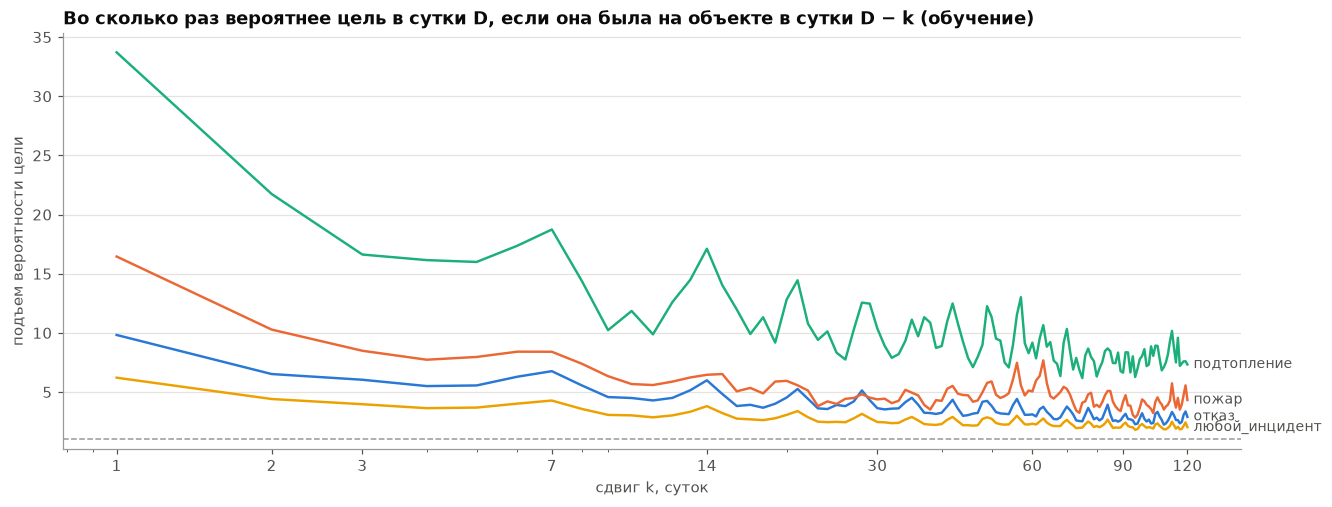

,1,2,3,7,14,21,30,60,90,120
отказ,9.800,6.500,6.000,6.800,6.000,5.300,3.600,3.100,2.900,2.900
пожар,16.500,10.300,8.500,8.400,6.500,5.600,4.400,5.000,4.200,4.300
подтопление,33.700,21.700,16.600,18.700,17.100,14.400,10.400,9.200,6.600,7.300
любой_инцидент,6.200,4.400,4.000,4.300,3.800,3.400,2.500,2.300,2.300,2.000


In [8]:
def lag_lift(t, lags):
    y = grid.pivot(index="день", columns="ид_объект", values=f"цель_{t}").astype(float)
    ok = grid.assign(ok=OK & (SPLIT == "обучение")).pivot(index="день", columns="ид_объект", values="ok")
    y = y.where(ok.astype(bool)).to_numpy()
    base = np.nanmean(y)
    out = {}
    for k in lags:
        a, b = y[k:], y[:-k]
        sel = (b == 1) & ~np.isnan(a)
        out[k] = np.nanmean(a[sel]) / base
    return pd.Series(out)


LAGS = np.arange(1, 121)
lag_tab = pd.DataFrame({t: lag_lift(t, LAGS) for t in MODEL_TARGETS})
fig, ax = plt.subplots(figsize=(12, 4.5))
for t in MODEL_TARGETS:
    ax.plot(lag_tab.index, lag_tab[t], color=TARGET_COLOR[t], lw=1.6)
    ax.annotate(t, (lag_tab.index[-1], lag_tab[t].iloc[-1]), xytext=(4, 0), textcoords="offset points",
                color=INK2, va="center", fontsize=9)
ax.axhline(1, color=GREY, lw=1, ls="--")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}"))
ax.set_xticks([1, 2, 3, 7, 14, 30, 60, 90, 120])
ax.set_xlabel("сдвиг k, суток")
ax.set_ylabel("подъем вероятности цели")
ax.set_title("Во сколько раз вероятнее цель в сутки D, если она была на объекте в сутки D − k (обучение)")
plt.show()
display(lag_tab.loc[[1, 2, 3, 7, 14, 21, 30, 60, 90, 120]].T.round(1))

**Результат.** Подъем максимален на сдвиге в одни сутки: если цель была вчера, отказ сегодня вероятнее в 9,8 раза,
пожар – в 16,5, подтопление – в 33,7, любой инцидент – в 6,2 раза. Уже на вторые сутки подъем падает примерно на
треть (6,5; 10,3; 21,7; 4,4) и дальше до конца недели держится почти ровно (на 7-е сутки 6,8; 8,4; 18,7; 4,3).
К 30-м суткам он снижается еще (3,6; 4,4; 10,4; 2,5), а с 60-х по 120-е выходит на плато: около 3 для отказа,
4-5 для пожара, 7-9 для подтопления, 2,0-2,3 для любого инцидента. Плато не затухает. Оно отражает уже не память о
конкретном эпизоде, а постоянную склонность объекта.

**Вывод – четыре окна по четырем участкам кривой:** 1 сутки (острый всплеск вчерашнего дня), 7 суток (ровный
участок первой недели), 30 суток (спад) и 90 суток (плато, «репутация» объекта). Окна длиннее не нужны: на 120-х
сутках подъем тот же, что на 60-90-х.

## 2. История объекта по классам инцидентов

**Почему группа может работать.** Раздел 1 показал, что цель «помнит» свое прошлое на объекте. Если к тому же
проблемные объекты остаются проблемными из года в год, то история объекта – это не только краткая память о
вчерашнем сбое, но и долгая «репутация» объекта.

### 2.1 Устойчивы ли проблемные объекты
**Проверка.** Для каждого объекта и года считаем долю суток с целью (только сутки без масок, объект должен
иметь не меньше 100 рабочих суток в году) и ранговую корреляцию Спирмена этих долей между соседними годами
обучающего периода. Корреляция около 1 – объекты сохраняют свой ранг риска, около 0 – каждый год проблемные
объекты новые.

In [9]:
def yearly_share(t):
    d = grid.loc[OK, ["ид_объект", "день", f"цель_{t}"]]
    g = d.assign(год=d["день"].dt.year).groupby(["ид_объект", "год"])[f"цель_{t}"].agg(["mean", "size"])
    return g["mean"].where(g["size"] >= 100).unstack("год")


def spearman(a, b):
    """Ранговая корреляция по общим непропущенным значениям."""
    m = a.notna() & b.notna()
    return a[m].rank().corr(b[m].rank())


stab = {}
for t in MODEL_TARGETS:
    s = yearly_share(t)
    stab[t] = {f"{y}→{y + 1}": spearman(s[y], s[y + 1]) for y in range(2019, 2024)}
stab = pd.DataFrame(stab).T
s = yearly_share("отказ")
stab["объектов_в_паре_(мин)"] = min(int((s[y].notna() & s[y + 1].notna()).sum()) for y in range(2019, 2024))
display(stab.round(2))

,2019→2020,2020→2021,2021→2022,2022→2023,2023→2024,объектов_в_паре_(мин)
отказ,0.790,0.790,0.730,0.790,0.810,47
пожар,0.980,0.980,0.930,0.990,0.980,47
подтопление,0.770,0.990,0.820,0.790,0.830,47
любой_инцидент,0.830,0.850,0.840,0.870,0.820,47


**Результат.** Корреляция высокая у всех целей: у пожара 0,93-0,99, у подтопления 0,77-0,99, у любого инцидента
0,82-0,87, у отказа 0,73-0,81 (в каждой паре лет не меньше 47 объектов). Проблемные объекты действительно остаются
проблемными, особенно по пожару: набор «горящих» объектов почти не меняется из года в год. Самое низкое значение у
отказа (0,73) приходится на пару 2021→2022, то есть на первый полный год после перехода СМВУ.

**Вывод.** Длинные окна истории (30 и 90 суток) и постоянные свойства объекта должны работать, и сильнее всего для
пожара.

### 2.2 Признаки истории
Из эпизодов, разложенных по дню известности, строим суточные ряды объекта и сворачиваем их в окна
1, 7, 30 и 90 суток (`fe.window_sums` суммирует ряд за сутки `[D − w, D − 1]`, сами сутки `D` в окно не входят).
Классы – отказ, подтопление, пожар, газ, потеря связи, проникновение, неисправность охраны и «любой_инцидент»
(отказ, подтопление, пожар, газ или потеря связи). Историю неисправности охраны строим так же, как газа: это
частотная цель, и ее собственное прошлое – главный кандидат для ее фоновой оценки.

- `дней_<класс>_<w>д` – сколько суток окна на объекте был длинный эпизод класса. Это прямое прошлое самой цели;
- `доля_дней_<класс>_<w>д` – то же, деленное на число суток окна без маски (`fe.window_shares`, окна 7, 30 и 90
  суток). Сутки под маской выпадают и из числителя, и из знаменателя, а тихие сутки подключенного объекта – это
  ноль в числителе и единица в знаменателе. Почему знаменатель важен, проверим в 2.3;
- `дней_с_последнего_<класс>` – сколько суток прошло с последних суток с эпизодом; если эпизода еще не было,
  ставим 3 650 и флаг `не_было_<класс>` (`fe.days_since_last`);
- `эпизодов_<класс>_<w>д` и `коротких_<класс>_<w>д` – число длинных эпизодов и число коротких (дребезг, меньше
  минуты; для потери связи – меньше 10 минут) за 1, 7, 30 суток. Сюда же откачка («Работают все насосы в АНС»)
  и вывод из работы («Отключено устройство»): они не цели, но могут предвещать цели. Гипотеза: дребезг –
  ранний симптом настоящего отказа;
- `эпизодов_<класс>_30д_на_канал` – число эпизодов за 30 суток на один канал тех типов, которые дают этот класс.
  Большой объект с сотней дымовых датчиков сбоит чаще просто потому, что датчиков больше;
- `доля_дней_окна_без_данных_30д` – доля суток из последних 30, которые под маской: модель должна знать, насколько
  полна история.

Типы датчиков, которые дают класс, определяем по данным: типы, на которые приходится не меньше 1 % длинных
эпизодов класса в обучающем периоде.

In [10]:
TRAIN_END = pd.Timestamp("2025-01-01")

tr = ev_all[ev_all["длинный"] & (ev_all["день"] < TRAIN_END) & (ev_all["ид_канала_данных"] >= 0)]
type_share = tr.groupby("класс")["тип_датчика"].value_counts(normalize=True)
CLASS_TYPES = {c: sorted(type_share[c][type_share[c] >= 0.01].index) for c in fi.PER_CHANNEL}
# статичные таблицы для строителей: справочник, типы датчиков классов, число каналов по объектам, родители
ctx = fi.make_context(channels, CLASS_TYPES, start=DAYS[0])
for c in fi.PER_CHANNEL:
    print(f"{c}: {', '.join(CLASS_TYPES[c])}; каналов на объект – медиана {ctx['n_ch'][c].median():.0f}, "
          f"максимум {ctx['n_ch'][c].max():.0f}")


def describe_history(c):
    w = window_of(c)
    for pat, text in [
        (r"^дней_с_последнего_(.+)$", "суток с последних суток, когда был длинный эпизод класса «{0}» (3 650 – не было)"),
        (r"^не_было_(.+)$", "флаг: на объекте еще не было длинного эпизода класса «{0}»"),
        (r"^доля_дней_окна_без_данных_30д$", "доля суток из последних 30 с маской (объект не подключен, не на связи, "
                                             "сбой)"),
        (r"^доля_дней_(.+)_\d+д$", "доля суток с длинным эпизодом класса «{0}» среди суток окна без маски"),
        (r"^дней_(.+)_\d+д$", "суток окна, когда был длинный эпизод класса «{0}»"),
        (r"^эпизодов_(.+)_30д_на_канал$", "длинных эпизодов класса «{0}» за 30 суток на канал типов этого класса"),
        (r"^эпизодов_(.+)_\d+д$", "длинных эпизодов класса «{0}» в окне"),
        (r"^коротких_(.+)_\d+д$", "коротких эпизодов (дребезг) класса «{0}» в окне"),
    ]:
        m = re.match(pat, c)
        if m:
            return text.format(*m.groups()) + (f", окно {w} сут." if w and "окна" not in text else "")
    return c


S = {"eps": eps_raw, "cl": cl_raw, "ev": ev_all, "ods": ods, "dc": daily_channel, "mg": meas_gaps,
     "ud": undefined_daily, "ub": undefined_bursts, "ht": hourly_type, "ppr": ppr_win, "mask": grid[KEY + ["маска"]]}
t0 = time.time()
hist = fi.build_history(S, grid, ctx)
HIST_COLS = add(hist, "история объекта", describe_history)
print(f"признаков истории: {len(HIST_COLS)}, {time.time() - t0:.0f} с")

отказ: Датчик дыма, Датчик температуры, ИБП, Состояние вентилятора, Состояние насоса, Состояние фазы; каналов на объект – медиана 24, максимум 875
подтопление: Состояние насоса; каналов на объект – медиана 0, максимум 30
пожар: Датчик дыма; каналов на объект – медиана 0, максимум 875
газ: Газовый датчик; каналов на объект – медиана 0, максимум 79
проникновение: КД АВ; каналов на объект – медиана 0, максимум 46
неисправность_охраны: Состояние охраны; каналов на объект – медиана 1, максимум 1


признаков истории: 133, 1 с


Сначала убедимся, что суточный ряд «был ли длинный эпизод класса» действительно воспроизводит целевую. Сдвиг по
дню известности и исключение замаскированных суток должны оставить совпадение почти полным.

In [11]:
cd = grid[KEY].merge(fi.class_days(ev_all), on=KEY, how="left").fillna(0)
agree = pd.Series({t: (cd[t].to_numpy()[OK] == Y[t][OK]).mean() for t in fi.HIST_ALL})
recall = pd.Series({t: cd[t].to_numpy()[OK & (Y[t] == 1)].mean() for t in fi.HIST_ALL})
display(pd.DataFrame({"совпадение_суток": agree, "доля_положительных_суток_цели_в_ряду": recall}).T
        .style.format("{:.3%}"))

,отказ,подтопление,пожар,газ,потеря_связи,проникновение,неисправность_охраны,любой_инцидент
совпадение_суток,100.000%,100.000%,100.000%,100.000%,99.999%,99.998%,100.000%,99.999%
доля_положительных_суток_цели_в_ряду,100.000%,100.000%,100.000%,100.000%,99.762%,99.994%,100.000%,99.988%


Типы датчиков, которые дают класс. У отказа их шесть: дым, температура, ИБП, вентилятор, насос и фаза (медиана 24
таких канала на объект, максимум 875). Газовых датчиков среди них больше нет: после маски плановых работ на них
приходится меньше 1 % длинных отказов обучения (часть их отказов приходилась на дни, когда датчики сняты на
поверку). У пожара это только дымовые датчики, у подтопления только
насосы, у газа газовые датчики, у проникновения КД АВ, у неисправности охраны – «Состояние охраны» (один канал на
объект). У большинства объектов каналов пожара, подтопления, газа и проникновения нет (медиана 0), и нормированный
признак у них – пропуск.

Суточный ряд совпадает с целевой в 100 % рабочих суток для отказа, подтопления, пожара, газа и неисправности охраны.
Для потери связи в ряду есть 99,762 % положительных суток цели, для проникновения 99,994 %, для любого инцидента
99,988 %. Расхождения – как раз эпизоды, которые стали длинными только после полуночи: в целевой они относятся к
суткам начала, а в истории к следующим. Значит, история в признаках – та же целевая, только без заглядывания вперед.

Теперь сигнал. Самая показательная часть – «диагональ»: как признаки класса предсказывают цель того же класса.

In [12]:
hist_sig = show(HIST_COLS, top=25)
diag = {}
for t in MODEL_TARGETS:
    diag[t] = {kind: hist_sig.loc[kind.replace("{}", t), f"подъем_{t}"] for kind in
               ["дней_{}_1д", "дней_{}_7д", "дней_{}_30д", "дней_{}_90д", "доля_дней_{}_30д", "доля_дней_{}_90д",
                "дней_с_последнего_{}"]}
    if t != "любой_инцидент":
        for kind in ["эпизодов_{}_1д", "эпизодов_{}_7д", "эпизодов_{}_30д", "эпизодов_{}_30д_на_канал",
                     "коротких_{}_1д", "коротких_{}_7д", "коротких_{}_30д"]:
            diag[t][kind] = hist_sig.loc[kind.replace("{}", t), f"подъем_{t}"]
display(pd.DataFrame(diag).round(2))
GUARD = "неисправность_охраны"
print(f"цель «{GUARD}»: сильнейшие признаки истории (обучение без масок)")
display(fe.signal_table(X.loc[TRAIN, HIST_COLS], Y[GUARD][TRAIN]).head(6)
        .style.format({"pr_auc": "{:.4f}", "доля_положительных": "{:.3%}", "подъем_pr_auc": "{:.2f}",
                       "доля_пропусков": "{:.1%}"}))

,подъем_отказ,подъем_пожар,подъем_подтопление,подъем_любой_инцидент,доля_пропусков,psi_валидация,psi_эпоха
дней_с_последнего_подтопление,1.80,1.22,19.05,2.05,0.0%,0.05,0.02
доля_дней_подтопление_30д,1.59,1.07,14.73,1.71,0.1%,0.00,0.00
эпизодов_подтопление_7д,1.44,1.03,14.45,1.57,0.0%,0.00,0.00
доля_дней_подтопление_7д,1.40,1.03,14.34,1.57,0.2%,0.00,0.01
доля_дней_подтопление_90д,1.81,1.11,14.20,1.81,0.1%,0.00,0.01
дней_подтопление_7д,1.35,1.03,13.42,1.54,0.0%,0.01,0.00
эпизодов_подтопление_30д,1.55,1.07,12.67,1.62,0.0%,0.00,0.00
дней_подтопление_30д,1.47,1.07,12.53,1.63,0.0%,0.00,0.02
эпизодов_подтопление_1д,1.22,1.01,11.73,1.36,0.0%,0.00,0.00
дней_подтопление_90д,1.48,1.11,11.10,1.61,0.0%,0.01,0.01


,отказ,пожар,подтопление,любой_инцидент
дней_{}_1д,3.510,4.650,9.660,2.570
дней_{}_7д,5.640,6.960,13.420,3.900
дней_{}_30д,5.500,6.260,12.530,3.760
дней_{}_90д,4.700,6.270,11.100,3.360
доля_дней_{}_30д,6.130,6.740,14.730,4.090
доля_дней_{}_90д,5.740,7.090,14.200,3.890
дней_с_последнего_{},5.530,7.660,19.050,3.710
эпизодов_{}_1д,4.240,6.350,11.730,NaN
эпизодов_{}_7д,4.520,4.480,14.450,NaN
эпизодов_{}_30д,4.040,3.490,12.670,NaN


цель «неисправность_охраны»: сильнейшие признаки истории (обучение без масок)


,признак,pr_auc,доля_положительных,подъем_pr_auc,доля_пропусков
54,доля_дней_неисправность_охраны_90д,0.1289,2.042%,6.31,0.1%
30,дней_неисправность_охраны_90д,0.1248,2.041%,6.11,0.0%
46,доля_дней_неисправность_охраны_30д,0.1143,2.043%,5.60,0.1%
22,дней_неисправность_охраны_30д,0.1109,2.041%,5.43,0.0%
95,эпизодов_неисправность_охраны_30д,0.1004,2.041%,4.92,0.0%
86,эпизодов_неисправность_охраны_7д,0.0915,2.041%,4.48,0.0%


**Результат.**

- История цели работает для всех четырех целей. Лучшая форма у отказа и любого инцидента – **доля** суток с эпизодом
  за 30 суток: подъем 6,13 и 4,09. У пожара и подтопления сильнее всего **сколько суток прошло с последнего
  эпизода**: 7,66 и 19,05 (доли у них 6,74-7,09 и 14,20-14,73). Пожары и подтопления идут сериями.
- На окнах 30 и 90 суток доля обходит сырой счетчик у всех целей (за 90 суток: отказ 5,74 против 4,70, пожар
  7,09 против 6,27, подтопление 14,20 против 11,10), на окне 7 суток они близки. На строках, где в окне нет суток под маской, доля и счетчик отличаются только
  постоянным делителем, так что разница создается строками с неполным окном; это проверено отдельно в 2.4.
- Вчерашние сутки сами по себе слабее недели (отказ 3,51 против 5,64 у окна 7 суток): одиночные сутки шумят, окно
  их сглаживает. Короткое окно все равно сохраняем, потому что оно ловит острый всплеск. Если оно окажется
  дублем, отбор в разделе 10 его уберет.
- Число длинных эпизодов дает чуть меньше, чем число суток с эпизодами (отказ за 7 суток 4,52 против 5,64).
- **Дребезг** (короткие эпизоды) тоже предсказывает цель, но слабее длинных эпизодов: отказ 2,58-3,18, пожар
  2,68-3,07, подтопление 5,19-8,01. Гипотеза «дребезг предвещает отказ» подтверждается частично. Сигнал есть, но
  меньше, чем у самих длинных эпизодов; по всей видимости, дребезг просто указывает на тот же проблемный канал.
- **Нормировка на число каналов** не помогает ни одной цели: отказ 2,88 против 4,04 у сырого числа эпизодов за
  30 суток, пожар 1,09 против 3,49, подтопление 2,66 против 12,67. Возможное объяснение: у пожара и подтопления
  нормированный признак определен только на объектах с дымовыми датчиками или насосами, а внутри этой группы большое
  число датчиков само по себе фактор риска, и деление его убирает. Решение оставляем отбору.
- Есть перекрестные связи: `дней_с_последнего_газ` поднимает подтопление в 4,77 раза, `коротких_откачка_30д` – в
  6,39 раза. Газ, откачка и вода встречаются на одних и тех же объектах.
- Неисправность охраны тоже хорошо предсказывается своей историей, причем длинной: доля суток с ней за 90 суток
  дает подъем 6,31, за 30 суток – 5,60, время с последнего эпизода – 4,48. Это свойство объекта, а не острый
  всплеск: для частотной оценки этого класса окно 30-90 суток подходит.

### 2.3 Знаменатель долей
Доля суток с эпизодом – отношение, и от знаменателя зависит, что она значит. Часть объектов пишет в журнал редко:
у них в основном дискретные датчики, которые присылают запись только при смене состояния. Если делить число суток с
эпизодом только на сутки, когда объект что-то прислал, у такого объекта почти каждые сутки с записями окажутся
сутками с эпизодом (эпизод сам порождает записи), и доля выйдет сильно завышенной. Правильный знаменатель – все сутки
окна, когда объект подключен и на связи, то есть сутки без маски: тихие сутки – обычный день без события.

**Проверка.** Считаем обе доли за 30 суток и сравниваем их среднее с фактической долей суток с целью на тех же
строках обучения. Объекты делим на пишущие редко (записи меньше чем в половине рабочих суток обучения) и пишущие
почти каждый день. Хорошая оценка частоты должна совпадать с фактом в обеих группах.

In [13]:
rec = (daily_channel.merge(channels[["ид_канала_данных", "ид_объект"]], on="ид_канала_данных")
       .groupby(KEY)["количество_событий"].sum().rename("записей").reset_index())
ACTIVE = grid[KEY].merge(rec, on=KEY, how="left")["записей"].fillna(0).to_numpy() > 0
vd30 = fe.valid_days(grid, [30])["дней_с_данными_30д"].to_numpy()
act30 = fe.window_sums(grid, grid.loc[OK & ACTIVE, KEY].assign(_a=1.0), ["_a"], [30])["_a_30д"].to_numpy()
obj_active = pd.Series(ACTIVE[TRAIN]).groupby(grid["ид_объект"].to_numpy()[TRAIN]).mean()
RARE = grid["ид_объект"].isin(obj_active.index[obj_active < 0.5]).to_numpy()
print(f"рабочих суток обучения с записями: {ACTIVE[TRAIN].mean():.1%}; объектов, которые пишут меньше чем в половину "
      f"рабочих суток: {(obj_active < 0.5).sum()} из {len(obj_active)}")
rows = []
for t in ["отказ", "любой_инцидент"]:
    new = X[f"доля_дней_{t}_30д"].to_numpy()
    num = new * vd30
    old = num / np.where(act30 > 0, act30, np.nan)          # знаменатель – только сутки с записями
    for name, m in [("пишут редко", TRAIN & RARE), ("пишут почти каждый день", TRAIN & ~RARE)]:
        m = m & ~np.isnan(old) & ~np.isnan(new)
        rows.append({"цель": t, "объекты": name, "строк": int(m.sum()),
                     "доля_по_суткам_с_записями": old[m].mean(), "доля_по_суткам_без_маски": new[m].mean(),
                     "фактическая_доля_суток_с_целью": Y[t][m].mean()})
display(pd.DataFrame(rows).set_index(["цель", "объекты"]).style.format(
    {"строк": "{:,.0f}", "доля_по_суткам_с_записями": "{:.2%}", "доля_по_суткам_без_маски": "{:.2%}",
     "фактическая_доля_суток_с_целью": "{:.2%}"}))
# пример: объект, который пишет реже всех среди объектов с отказами, в сутки, когда за 30 суток у него был отказ
had = TRAIN & (X["дней_отказ_30д"].to_numpy() > 0)
ex_obj = obj_active.reindex(np.unique(grid["ид_объект"].to_numpy()[had])).idxmin()
m = had & (grid["ид_объект"] == ex_obj).to_numpy()
i = np.flatnonzero(m)[len(np.flatnonzero(m)) // 2]
display(pd.DataFrame({"объект": [ex_obj], "сутки_D": [f"{grid.at[i, 'день']:%Y-%m-%d}"],
                      "суток_без_маски_из_30": [vd30[i]], "из_них_с_записями": [act30[i]],
                      "суток_с_отказом": [X.at[i, "дней_отказ_30д"]],
                      "доля_по_суткам_с_записями": [X.at[i, "дней_отказ_30д"] / act30[i]],
                      "доля_дней_отказ_30д": [X.at[i, "доля_дней_отказ_30д"]]}).style.format(
    {"доля_по_суткам_с_записями": "{:.3f}", "доля_дней_отказ_30д": "{:.3f}", "суток_без_маски_из_30": "{:.0f}",
     "из_них_с_записями": "{:.0f}", "суток_с_отказом": "{:.0f}"}))

рабочих суток обучения с записями: 69.9%; объектов, которые пишут меньше чем в половину рабочих суток: 26 из 74


,объект,сутки_D,суток_без_маски_из_30,из_них_с_записями,суток_с_отказом,доля_по_суткам_с_записями,доля_дней_отказ_30д
0,4770,2022-05-03,30,2,1,0.500,0.033


**Результат.** Записи есть в 69,9 % рабочих суток обучения, и 26 из 74 объектов (с рабочими сутками в обучении)
пишут меньше чем в половину суток. У них доля по суткам с записями завышена в 4-4,5 раза: для отказа 10,30 % против
фактических 2,49 %, для любого инцидента 15,71 % против 3,47 %. Доля по всем суткам без маски почти совпадает с
фактом: 2,58 % и 3,63 %. У объектов, которые пишут почти каждый день, обе доли близки к факту (отказ 3,39 % и 3,21 %
при фактических 3,14 %), потому что почти все их сутки и так с записями.

Пример – объект 4770, сутки 2022-05-03: из 30 суток окна все 30 без маски, записи были только в двое из них, и в одни
из этих двух случился отказ. Доля по суткам с записями равна 0,500 («отказ через день»), правильная доля – 0,033
(один отказ за месяц).

**Вывод.** Все доли суток в признаках и в частотном прогнозе (раздел 11) считаются по суткам без маски.


### 2.4 Грязные окна
У 20 % строк сетки есть маска, и часть рабочих строк видит в своем окне сутки под маской (например, объект
подключили меньше 30 суток назад). Проверим, не ломает ли это признаки: сравним подъем сырого счетчика и доли за
30 суток отдельно на строках с полным окном (все 30 суток без маски) и с неполным.

In [14]:
clean = (X["доля_дней_окна_без_данных_30д"] == 0).to_numpy()
rows = []
for t in ["отказ", "пожар", "любой_инцидент"]:
    for name, m in [("полное окно", TRAIN & clean), ("неполное окно", TRAIN & ~clean)]:
        st = fe.signal_table(X.loc[m, [f"дней_{t}_30д", f"доля_дней_{t}_30д"]], Y[t][m]).set_index("признак")
        rows.append({"цель": t, "строки": name, "строк": int(m.sum()), "доля_положительных": Y[t][m].mean(),
                     "подъем_счетчика": st.loc[f"дней_{t}_30д", "подъем_pr_auc"],
                     "подъем_доли": st.loc[f"доля_дней_{t}_30д", "подъем_pr_auc"]})
display(pd.DataFrame(rows).set_index(["цель", "строки"]).style.format(
    {"строк": "{:,.0f}", "доля_положительных": "{:.2%}", "подъем_счетчика": "{:.2f}", "подъем_доли": "{:.2f}"}))

**Результат.** На строках с полным окном счетчик и доля отличаются только постоянным делителем 30, поэтому подъемы
у них совпадают: 5,54 для отказа, 6,59 для пожара, 3,90 для любого инцидента. На строках с неполным окном (19 930
строк обучения из 130 104) доля заметно сильнее счетчика: отказ 9,04 против 5,98, пожар 6,23 против 5,01, любой
инцидент 4,61 против 3,23. Гипотеза подтверждается: у объекта, который часть окна был под маской, сырой счетчик
занижен, а нормировка это исправляет. Поэтому в матрице есть и доли, и `доля_дней_окна_без_данных_30д`.

Частота целей на строках с неполным окном почти та же, что на полных (отказ 2,83 % против 2,92 %), а пожар и любой
инцидент даже чаще (1,91 % против 1,35 % и 5,36 % против 4,78 %). Выбрасывать такие строки как второсортные нельзя.

### 2.5 Часы с последнего эпизода и возраст открытого эпизода
**Почему группа может работать.** Счет в сутках груб в самом важном месте: эпизод, ставший известным вчера в 00:05,
и эпизод, ставший известным в 23:55, дают одинаковое «одни сутки назад». Раздел 1 показал, что риск сильнее всего
сразу после эпизода и быстро спадает, поэтому разница в 24 часа может быть существенной. Вторая неучтенная деталь –
эпизод, который начался до полуночи и еще идет: канал, застрявший в отказе на неделю, и канал, сработавший за
минуту до полуночи, – разные ситуации.

- `часов_с_последнего_<класс>` (`fe.hours_since_last`) – часов от момента известности последнего длинного эпизода
  класса (строго до `D 00:00`) до полуночи; эпизода не было или он дальше 720 часов (30 суток) – 720. Классы: отказ,
  пожар, подтопление, газ, потеря связи, проникновение, откачка, неисправность охраны и любой инцидент;
- `часов_открыт_<класс>_макс` (`fe.open_age_at_midnight`) – возраст в часах самого старого эпизода класса, который
  начался до `D 00:00` и в полночь еще не закончился (нет открытых – 0); для отказа, пожара и подтопления.

**Проверка.** Сигнал группы по модельным целям и прямое сравнение: часы с последнего эпизода против суток с
последнего эпизода того же класса. Для открытых эпизодов – доля суток с целью при открытом в полночь эпизоде и без
него.

In [15]:
def describe_hours(c):
    for pat, text in [
        (r"^часов_с_последнего_(.+)$", "часов от момента, когда стал известен последний длинный эпизод класса «{0}», "
                                       f"до D 00:00 (не было или дальше {fi.HOURS_CAP} ч – {fi.HOURS_CAP})"),
        (r"^часов_открыт_(.+)_макс$", "возраст в часах самого старого эпизода класса «{0}», открытого в D 00:00 "
                                      "(нет открытых – 0)"),
    ]:
        m = re.match(pat, c)
        if m:
            return text.format(*m.groups())
    return c


t0 = time.time()
HOURS_COLS = add(fi.build_hours(S, grid, ctx), "часы с последнего эпизода", describe_hours)
print(f"признаков часов: {len(HOURS_COLS)}, {time.time() - t0:.0f} с")
hours_sig = show(HOURS_COLS)
cmp = {}
for t in MODEL_TARGETS + [GUARD]:
    cols = [f"часов_с_последнего_{t}", f"дней_с_последнего_{t}"]
    st = fe.signal_table(X.loc[TRAIN, cols], Y[t][TRAIN]).set_index("признак")["подъем_pr_auc"]
    cmp[t] = {"часов_с_последнего": st[cols[0]], "дней_с_последнего": st[cols[1]]}
    if t in fi.OPEN_AGE_CLASSES:
        opened = X.loc[TRAIN, f"часов_открыт_{t}_макс"].to_numpy() > 0
        cmp[t]["строк_с_открытым_эпизодом"] = opened.mean()
        cmp[t]["доля_цели_при_открытом"] = Y[t][TRAIN][opened].mean()
        cmp[t]["доля_цели_без_открытого"] = Y[t][TRAIN][~opened].mean()
display(pd.DataFrame(cmp).T.style.format("{:.2f}", na_rep="")
        .format("{:.2%}", subset=["строк_с_открытым_эпизодом", "доля_цели_при_открытом", "доля_цели_без_открытого"],
                na_rep=""))

признаков часов: 12, 0 с


,подъем_отказ,подъем_пожар,подъем_подтопление,подъем_любой_инцидент,доля_пропусков,psi_валидация,psi_эпоха
часов_с_последнего_подтопление,1.58,1.07,21.73,1.92,0.0%,0.01,0.00
часов_с_последнего_пожар,1.12,8.46,1.17,1.72,0.0%,0.00,0.00
часов_с_последнего_отказ,6.09,1.37,2.53,3.21,0.0%,0.00,0.02
часов_с_последнего_любой_инцидент,4.36,3.54,5.19,4.32,0.0%,0.00,0.01
часов_с_последнего_откачка,1.15,1.04,4.39,1.25,0.0%,0.01,0.02
часов_открыт_подтопление_макс,1.05,1.00,2.98,1.07,0.0%,0.00,0.00
часов_с_последнего_газ,1.32,1.03,2.75,1.20,0.0%,0.01,0.00
часов_с_последнего_проникновение,1.17,1.95,1.37,1.06,0.0%,0.01,0.00
часов_с_последнего_потеря_связи,1.04,1.34,1.04,1.71,0.0%,0.00,0.02
часов_с_последнего_неисправность_охраны,1.12,1.28,1.32,1.08,0.0%,0.01,0.02


,часов_с_последнего,дней_с_последнего,строк_с_открытым_эпизодом,доля_цели_при_открытом,доля_цели_без_открытого
отказ,6.09,5.53,8.53%,4.44%,2.76%
пожар,8.46,7.66,1.24%,7.56%,1.36%
подтопление,21.73,19.05,0.29%,20.22%,0.73%
любой_инцидент,4.32,3.71,,,
неисправность_охраны,5.59,4.48,,,


**Результат.** Часы сильнее суток для каждой цели: отказ 6,09 против 5,53, пожар 8,46 против 7,66, подтопление
21,73 против 19,05, любой инцидент 4,32 против 3,71, неисправность охраны 5,59 против 4,48. Для пожара, подтопления
и любого инцидента `часов_с_последнего_<цель>` – самый сильный одиночный признак из построенных до сих пор (у любого
инцидента 4,32 против 4,09 у доли за 30 суток), у отказа он вровень с долей суток с отказом за 30 суток (6,09 против
6,13). Гипотеза подтверждается: важно не только «были ли вчера», но и насколько близко к полуночи. Часы с последнего
любого инцидента помогают и частным целям (подтопление 5,19, пожар 3,54).

Открытый в полночь эпизод заметно повышает долю суток с той же целью: для подтопления 20,22 % против 0,73 %, для
пожара 7,56 % против 1,36 %, для отказа 4,44 % против 2,76 %. Но таких строк мало (0,29 %, 1,24 % и 8,53 %
обучения), поэтому одиночный подъем PR-AUC у возраста открытого эпизода скромный: 2,98 для подтопления, 1,25 для
пожара и 1,00 для отказа. Похожий признак – число каналов, открытых в полночь, – строим в разделе 3; если возраст
повторяет его, отбор оставит один из двух.


## 3. Каналы: сколько датчиков сбоит и как долго

**Почему группа может работать.** История объекта не различает «один датчик сбоит каждый день» и «каждый день
сбоит новый датчик». Для прогноза это разные ситуации: хронический канал почти наверняка даст эпизод и завтра,
а россыпь разных каналов говорит о проблеме объекта в целом (питание, контроллер). Кроме того, важно, что
происходит **прямо в полночь**: канал, который вошел в отказ вечером и так и не вернулся в норму, в следующие
сутки часто «дребезжит» и порождает новые эпизоды.

### 3.1 Когда канал становится хроническим
**Проверка.** На уровне отдельного канала: вероятность, что канал даст длинный эпизод отказа в сутки `D`, в
зависимости от числа его длинных эпизодов отказа за 30 предыдущих суток (обучение, сутки объекта без маски).
Порог «хронического» канала берем там, где эта вероятность становится высокой.

In [16]:
AX = fi.axes(grid)   # ось суток и объектов для матриц «сутки × объекты» и позиция строк сетки на ней
OK_MAT = np.zeros((len(OBJECTS), len(DAYS)), bool)
OK_MAT[AX.obj_idx, AX.day_idx] = TRAIN
# fi.channel_matrix: длинные эпизоды класса по каналам и дням известности («каналы × сутки»);
# fi.window_matrix: сумма по суткам [D − w, D − 1] для каждого канала
m_f, obj_f = fi.channel_matrix(ev_all, "отказ", DAYS)
w30 = fi.window_matrix(m_f, 30)
valid = OK_MAT[np.searchsorted(OBJECTS, obj_f)]
x, y = w30[valid], (m_f[valid] > 0)
bins = [1, 2, 3, 5, 10, 20, 30, 50, 100, np.inf]
lab = pd.cut(pd.Series(x), bins=bins, right=False)
chron = pd.DataFrame({"бин": lab, "y": y}).dropna().groupby("бин", observed=True)["y"].agg(["mean", "size"])
chron.columns = ["вероятность_эпизода_завтра", "канало_суток"]
chron.index = [f"{int(i.left)}-{int(i.right) - 1}" if np.isfinite(i.right) else f"{int(i.left)}+" for i in chron.index]
print(f"каналов с длинными отказами: {n(len(obj_f))}; вероятность эпизода у канала без эпизодов за 30 суток: "
      f"{y[x == 0].mean():.2%}")
display(chron.style.format({"вероятность_эпизода_завтра": "{:.1%}", "канало_суток": "{:,.0f}"}))

каналов с длинными отказами: 3 546; вероятность эпизода у канала без эпизодов за 30 суток: 0.23%


,вероятность_эпизода_завтра,канало_суток
1-1,1.5%,"183,363"
2-2,2.4%,"65,855"
3-4,3.0%,"51,747"
5-9,4.9%,"27,454"
10-19,4.1%,"17,802"
20-29,4.5%,"6,763"
30-49,7.0%,"1,829"
50-99,2.2%,"1,891"
100+,0.0%,781


**Результат.** Длинные отказы были у 3 546 каналов. Канал без эпизодов за 30 суток дает эпизод на следующие сутки с
вероятностью 0,23 %. После одного эпизода вероятность 1,5 %, после двух 2,4 %, после 3-4 уже 3,0 %. С пяти эпизодов
она выходит на плато 4-7 % (5-9 эпизодов – 4,9 %, 10-19 – 4,1 %, 20-29 – 4,5 %, 30-49 – 7,0 %). У каналов с 50-99
эпизодами за месяц вероятность падает до 2,2 %, со 100 и больше – до нуля (781 канало-сутки). Возможное объяснение
(здесь не проверяли): такие каналы застревают в одном состоянии или их выводят из работы, и новых эпизодов они не
начинают.

**Вывод.** Порог хронического канала – 5 длинных эпизодов за 30 суток. Выше него рост числа эпизодов риска уже не
добавляет.

In [17]:
assert fi.N_CHRONIC == 5   # порог хронического канала в коде признаков – вывод из таблицы выше


def describe_channels(c):
    for pat, text in [
        (r"^каналов_с_(.+)_(\d+)д$", "разных каналов с длинным эпизодом класса «{0}» за {1} суток"),
        (r"^хронических_каналов_(.+)_30д$", "каналов, у которых за 30 суток не меньше " + str(fi.N_CHRONIC)
         + " длинных эпизодов класса «{0}»"),
        (r"^доля_коротких_отказ_30д$", "доля коротких среди всех эпизодов отказа за 30 суток"),
        (r"^каналов_в_(.+)_на_полночь$", "каналов, эпизод класса «{0}» у которых начался и не закончился к 00:00"),
    ]:
        m = re.match(pat, c)
        if m:
            return text.format(*m.groups())
    return c


t0 = time.time()
CH_COLS = add(fi.build_channels(S, grid, ctx), "каналы", describe_channels)
print(f"признаков каналов: {len(CH_COLS)}, {time.time() - t0:.0f} с")
ch_sig = show(CH_COLS)

признаков каналов: 13, 4 с


,подъем_отказ,подъем_пожар,подъем_подтопление,подъем_любой_инцидент,доля_пропусков,psi_валидация,psi_эпоха
каналов_с_подтопление_7д,1.26,1.03,11.97,1.47,0.0%,0.00,0.00
каналов_с_подтопление_30д,1.30,1.07,10.61,1.48,0.0%,0.00,0.00
каналов_с_пожар_7д,1.05,4.22,1.05,1.29,0.0%,0.00,0.00
каналов_с_отказ_7д,4.19,1.93,2.10,2.46,0.0%,0.00,0.01
каналов_в_подтопление_на_полночь,1.23,1.00,4.01,1.13,0.0%,0.00,0.00
каналов_с_отказ_30д,3.55,2.01,1.66,2.32,0.0%,0.01,0.02
каналов_с_пожар_30д,1.05,3.33,1.18,1.20,0.0%,0.00,0.00
хронических_каналов_отказ_30д,2.70,1.39,1.72,1.78,0.0%,0.00,0.00
хронических_каналов_пожар_30д,1.00,2.49,1.03,1.12,0.0%,0.00,0.00
каналов_в_пожар_на_полночь,1.00,1.55,1.01,1.05,0.0%,0.00,0.04


**Результат.** Число разных каналов с эпизодом сильно предсказывает подтопление (7 суток – 11,97) и пожар (4,22), но
почти наверняка дублирует историю объекта: у этих классов эпизоды дает один тип датчика, и «сколько каналов»
близко к «сколько эпизодов». Для отказа число каналов за 7 суток (4,19) слабее доли суток с отказом (6,13 за
30 суток). Хронические каналы дают 2,70 для отказа и 2,49 для пожара. Это меньше, чем у истории, но это другой
взгляд на ту же проблему.

Гипотеза о каналах, **застрявших в отказе к полуночи**, для самого отказа не подтвердилась: `каналов_в_отказ_на_полночь`
дает подъем 1,09 (для пожара 1,42). Для подтопления открытый к полуночи эпизод работает (4,01), для пожара слабее
(1,55). Каналы в выводе из работы на полночь почти не несут сигнала (не больше 1,17). Доля коротких эпизодов отказа
дает до 1,41, но пропущена в 47,6 % строк, где эпизодов не было. Решение по каждому признаку принимает отбор в
разделе 10: дубли уберет корреляция, слабые признаки – порог сигнала.

## 4. Потеря связи и активность каналов

**Почему группа может работать.** Потеря связи – это когда большая часть каналов объекта одновременно уходит в
«Неопределен». Ей могут предшествовать малые пачки: несколько каналов в «Неопределен» в одну минуту (сбоит модуль
контроллера), а также провал активности – объект вчера прислал заметно меньше записей или меньше каналов, чем
обычно. Историю самой потери связи (длинные и короткие эпизоды) мы уже посчитали в разделе 2, здесь добавляем
косвенные признаки:

- `минут_пачек_неопределен_<w>д` – минут, когда не меньше трех каналов объекта одновременно ушли в «Неопределен»
  (одиночный канал в «Неопределен» – обычный шум, три и больше в одну минуту – уже групповое событие);
- `неопределен_на_канал_7д` – записей «Неопределен» за 7 суток на один канал объекта;
- `активных_каналов_к_медиане_1д`, `записей_к_медиане_1д` – сколько каналов было активно и сколько записей
  пришло вчера, деленное на медиану за 28 суток по вчерашний день включительно; `доля_активных_каналов_1д` –
  активные вчера каналы к числу каналов объекта в справочнике.

In [18]:
COMM_DESCR = {
    "минут_пачек_неопределен_1д": "минут вчера, когда ≥ 3 каналов объекта одновременно ушли в «Неопределен»",
    "минут_пачек_неопределен_7д": "то же за 7 суток", "минут_пачек_неопределен_30д": "то же за 30 суток",
    "неопределен_на_канал_7д": "записей «Неопределен» за 7 суток на канал объекта",
    "активных_каналов_к_медиане_1д": "активных каналов вчера к медиане за 28 суток",
    "записей_к_медиане_1д": "записей вчера к медиане за 28 суток",
    "доля_активных_каналов_1д": "активных вчера каналов к числу каналов объекта в справочнике",
}
t0 = time.time()
COMM_COLS = add(fi.build_comm(S, grid, ctx), "связь и активность", COMM_DESCR.get)
print(f"признаков связи и активности: {len(COMM_COLS)}, {time.time() - t0:.0f} с")
comm_sig = show(COMM_COLS)
cl_cols = COMM_COLS + [c for c in HIST_COLS if "потеря_связи" in c and "доля" not in c]
display(fe.signal_table(X.loc[TRAIN, cl_cols], Y["потеря_связи"][TRAIN]).head(10)
        .style.format({"pr_auc": "{:.4f}", "доля_положительных": "{:.3%}", "подъем_pr_auc": "{:.2f}",
                       "доля_пропусков": "{:.1%}"}))

признаков связи и активности: 7, 1 с


,подъем_отказ,подъем_пожар,подъем_подтопление,подъем_любой_инцидент,доля_пропусков,psi_валидация,psi_эпоха
доля_активных_каналов_1д,1.56,1.22,2.72,1.55,0.0%,0.01,0.00
активных_каналов_к_медиане_1д,1.22,2.10,1.02,1.23,31.2%,0.00,0.01
минут_пачек_неопределен_1д,1.42,1.57,1.60,2.06,0.0%,0.00,0.00
минут_пачек_неопределен_7д,1.48,1.74,1.69,2.05,0.0%,0.00,0.02
минут_пачек_неопределен_30д,1.46,1.75,1.72,1.90,0.0%,0.01,0.06
записей_к_медиане_1д,1.12,1.83,1.01,1.20,31.2%,0.00,0.01
неопределен_на_канал_7д,1.26,1.23,1.61,1.65,0.0%,0.02,0.03


,признак,pr_auc,доля_положительных,подъем_pr_auc,доля_пропусков
0,минут_пачек_неопределен_1д,0.3909,0.280%,139.72,0.0%
8,дней_потеря_связи_7д,0.3773,0.280%,134.87,0.0%
14,эпизодов_потеря_связи_7д,0.3635,0.280%,129.93,0.0%
11,дней_с_последнего_потеря_связи,0.3387,0.280%,121.07,0.0%
9,дней_потеря_связи_30д,0.3256,0.280%,116.38,0.0%
13,эпизодов_потеря_связи_1д,0.3255,0.280%,116.33,0.0%
1,минут_пачек_неопределен_7д,0.2985,0.280%,106.69,0.0%
10,дней_потеря_связи_90д,0.2958,0.280%,105.73,0.0%
7,дней_потеря_связи_1д,0.2266,0.280%,81.00,0.0%
15,эпизодов_потеря_связи_30д,0.2172,0.280%,77.62,0.0%


**Результат.** Для модельных целей признаки связи и активности умеренные, лучший подъем по целям у каждого признака 1,6-2,7. Лучшие:
`доля_активных_каналов_1д` для подтопления (2,72) и отказа (1,56), `активных_каналов_к_медиане_1д` для пожара
(2,10) и пачки «Неопределен» для любого инцидента (2,06). У отношений к медиане пропущено 31,2 % строк: там медиана
за 28 суток равна нулю, то есть объект пишет реже чем через день.

Для самой потери связи картина другая. Вчерашние пачки «Неопределен» дают подъем 139,7 (PR-AUC 0,391 при доле
положительных 0,280 %), число суток с потерей связи за 7 суток – 134,9. Гипотеза, что малые пачки предвещают
потерю связи, подтверждается, но это не предвестник в узком смысле: потеря связи идет сериями, и вчерашние пачки
чаще всего принадлежат той же серии. Провал активности в первую десятку признаков для потери связи не попал.
Такие высокие подъемы – повод проверить утечку, это сделано в разделе 9.

## 5. Телеметрия: газ и температура

**Почему группа может работать.** У газовых датчиков и датчиков температуры кроме состояний есть числовые замеры.
Рост концентрации газа или необычная температура могут предшествовать тревоге, а молчание датчика – его отказу.
Но сначала нужно отделить настоящие значения от служебных кодов: контроллер при сбое пишет в поле значения
фиксированные числа, и если принять их за замер, «−127 градусов» станет самым сильным «сигналом».

### 5.1 Служебные коды
**Проверка.** Берем суточные минимумы и максимумы каналов и смотрим, какие точные значения чаще всего стоят на
хвостах: в нижнем 1 % минимумов и верхнем 1 % максимумов. Настоящий замер на хвосте размазан по многим значениям,
код – это одно и то же число сотни раз.

In [19]:
TEMP, GAS = fi.TEMP, fi.GAS
meas = (daily_channel[daily_channel["класс_записи"] == "измерение"]
        .merge(channels[["ид_канала_данных", "ид_объект", "тип_датчика"]], on="ид_канала_данных")
        .query("тип_датчика in @TEMP or тип_датчика in @GAS"))
tails = []
for тип, g in meas.groupby("тип_датчика"):
    lo = g["минимум_значения"][g["минимум_значения"] <= g["минимум_значения"].quantile(0.01)].round(2)
    hi = g["максимум_значения"][g["максимум_значения"] >= g["максимум_значения"].quantile(0.99)].round(2)
    for side, v in [("нижний 1 % минимумов", lo), ("верхний 1 % максимумов", hi)]:
        vc = v.value_counts().head(6)
        tails.append({"тип_датчика": тип, "хвост": side, "канало_суток_в_хвосте": len(v),
                      "частые_значения (канало-суток)": ", ".join(f"{k:g} ({c})" for k, c in vc.items())})
display(pd.DataFrame(tails))
print(f"канало-суток замеров: температура {n((meas['тип_датчика'] == TEMP).sum())}, газ {n((meas['тип_датчика'] == GAS).sum())}")

,тип_датчика,хвост,канало_суток_в_хвосте,частые_значения (канало-суток)
0,Газовый датчик,нижний 1 % минимумов,303930,"0 (301602), -0.01 (650), -2.56 (416), -0.02 (328), -0.04 (194), -0.03 (164)"
1,Газовый датчик,верхний 1 % максимумов,4714,"1.5 (788), 1.46 (448), 2.55 (411), 1.51 (337), 1.49 (328), 1.48 (320)"
2,Датчик температуры,нижний 1 % минимумов,5330,"-127 (5219), -3260 (42), -3276 (13), -3251 (11), -3266 (10), -3255 (9)"
3,Датчик температуры,верхний 1 % максимумов,3601,"33 (1801), 35 (601), 34 (558), 36 (204), 37 (125), 39 (45)"


канало-суток замеров: температура 357 085, газ 443 628


**Результат.** Коды видны сразу. Нижний 1 % суточных минимумов температуры почти целиком занимает одно значение −127
(5 219 канало-суток из 5 330), за ним идет семейство −3 276…−3 251. Это не морозы, а служебные значения
контроллера. Верхний хвост температуры – реальные 33-39 °C. У газа на хвостах стоят точные значения −2,56 (416
канало-суток) и 2,55 (411), а реальные максимумы рядом размазаны по значениям 1,46-1,51. Ноль – самое частое
значение минимума газа (301 602 канало-суток), и это нормальный замер: газа нет.

**Правило.** У температуры кодом считаем все, что лежит вне физически возможного диапазона −60…+90 °C (он
накрывает −127 и −3 276). У газа – точные значения 2,55, −2,56 и 327,68 (последнее – верх шкалы, встречается
редко).

In [20]:
# fi.code_days: кодом считаем температуру вне fi.TEMP_RANGE = (−60, 90) °C и точные значения газа fi.GAS_CODES
meas["код"] = fi.code_days(meas)
g = meas[meas["тип_датчика"] == GAS]
print("канало-суток газа с точным кодом:", {v: int(((g["минимум_значения"].round(2) == v)
                                                     | (g["максимум_значения"].round(2) == v)).sum()) for v in fi.GAS_CODES})
display(meas.groupby("тип_датчика")["код"].agg(["sum", "mean"]).rename(columns={"sum": "канало_суток_с_кодом",
                                                                                "mean": "доля"}))

канало-суток газа с точным кодом: {2.55: 411, -2.56: 416, 327.68: 5}


,канало_суток_с_кодом,доля
тип_датчика,,
Газовый датчик,615,0.001
Датчик температуры,5438,0.015


### 5.2 Признаки телеметрии
Все считаем по матрицам «сутки × каналы», затем сворачиваем по объекту. В сутки с кодом значения канала
считаем пропуском. «Вчера» – это сутки `D − 1`, «обычное» значение канала – медиана за 30 суток до вчерашних
(`D − 31 … D − 2`), так что и сравнение, и база целиком в прошлом.

- температура: `температура_макс_1д`, `температура_мин_1д` – крайние значения по объекту за вчера;
  `температура_откл_макс_1д`, `температура_откл_мин_1д` – наибольшее и наименьшее отклонение вчерашнего среднего
  канала от его обычного; `температура_ниже_3_<w>д`, `температура_выше_40_<w>д` – записи климатических
  состояний «Температура ниже 3ºC / выше 40ºC» (в классы инцидентов они не входят, но могут быть предвестником);
- газ: `газ_макс_1д` – максимум по объекту за вчера; `газ_превышение_1д` – наибольшее превышение вчерашнего
  максимума канала над его обычным максимумом (разность, а не отношение: обычный максимум часто 0,01-0,02,
  и отношение взрывается от шума); `газ_замеров_к_медиане_1д` – наименьшее по каналам отношение числа замеров
  вчера к медиане за 28 суток; `доля_газовых_без_замеров_1д` – доля газовых каналов, которые вчера молчали;
  `газ_доля_частого_опроса` – доля газовых каналов, у которых медианный интервал между замерами за 30 суток
  меньше 10 минут (у части объектов газ опрашивается часто, у остальных пачками раз в сутки);
- коды: `<тип>_каналов_с_кодом_<w>д` – канало-суток со служебным кодом за 1 и 7 суток;
- флаги `есть_газ`, `есть_температура`: у объекта вообще есть такие каналы. Где каналов нет, признаки телеметрии –
  пропуск (NaN), а не ноль: градиентный бустинг умеет отличать пропуск от значения.

In [21]:
TELE_DESCR = {
    "температура_каналов_с_кодом_1д": "каналов температуры со служебным кодом вчера",
    "температура_каналов_с_кодом_7д": "канало-суток температуры со служебным кодом за 7 суток",
    "газ_каналов_с_кодом_1д": "газовых каналов со служебным кодом вчера",
    "газ_каналов_с_кодом_7д": "канало-суток газа со служебным кодом за 7 суток",
    "температура_макс_1д": "максимальная температура по объекту вчера, °C",
    "температура_мин_1д": "минимальная температура по объекту вчера, °C",
    "температура_откл_макс_1д": "наибольшее отклонение вчерашней средней температуры канала от его медианы за 30 суток",
    "температура_откл_мин_1д": "наименьшее (самое отрицательное) такое отклонение",
    "газ_макс_1д": "максимальная концентрация газа по объекту вчера",
    "газ_превышение_1д": "наибольшее превышение вчерашнего максимума газового канала над его медианой за 30 суток",
    "газ_замеров_к_медиане_1д": "наименьшее по газовым каналам отношение числа замеров вчера к медиане за 28 суток",
    "доля_газовых_без_замеров_1д": "доля газовых каналов без единого замера вчера",
    "газ_доля_частого_опроса": "доля газовых каналов с медианным интервалом замеров меньше 10 минут за 30 суток",
    "температура_ниже_3_1д": "записей «Температура ниже 3ºC» вчера", "температура_ниже_3_7д": "то же за 7 суток",
    "температура_выше_40_1д": "записей «Температура выше 40ºC» вчера", "температура_выше_40_7д": "то же за 7 суток",
    "есть_газ": "у объекта есть газовые каналы", "есть_температура": "у объекта есть каналы температуры",
}
t0 = time.time()
TELE_COLS = add(fi.build_telemetry(S, grid, ctx), "телеметрия", TELE_DESCR.get)
print(f"признаков телеметрии: {len(TELE_COLS)}, {time.time() - t0:.0f} с")
tele_sig = show(TELE_COLS)
display(fe.signal_table(X.loc[TRAIN, TELE_COLS], Y["газ"][TRAIN]).head(6)
        .style.format({"pr_auc": "{:.4f}", "доля_положительных": "{:.3%}", "подъем_pr_auc": "{:.2f}",
                       "доля_пропусков": "{:.1%}"}))

признаков телеметрии: 19, 2 с


,подъем_отказ,подъем_пожар,подъем_подтопление,подъем_любой_инцидент,доля_пропусков,psi_валидация,psi_эпоха
есть_газ,1.73,1.21,4.03,1.51,0.0%,0.00,0.00
газ_макс_1д,1.21,3.27,1.78,1.27,87.4%,0.13,0.09
температура_мин_1д,1.95,1.78,1.27,1.71,71.3%,0.02,0.24
газ_превышение_1д,1.07,1.90,1.62,1.15,87.5%,0.09,0.02
доля_газовых_без_замеров_1д,1.16,1.83,1.45,1.08,86.5%,0.25,0.42
температура_ниже_3_1д,1.07,1.68,1.01,1.08,0.0%,0.00,0.00
температура_ниже_3_7д,1.04,1.67,1.04,1.08,0.0%,0.00,0.00
температура_макс_1д,1.17,1.59,1.63,1.34,71.3%,0.01,0.07
температура_каналов_с_кодом_1д,1.59,1.08,1.01,1.10,57.6%,0.00,0.00
температура_откл_макс_1д,1.32,1.06,1.56,1.13,76.2%,0.01,0.02


,признак,pr_auc,доля_положительных,подъем_pr_auc,доля_пропусков
17,есть_газ,0.0057,0.136%,4.18,0.0%
2,температура_макс_1д,0.0002,0.005%,3.96,71.3%
5,температура_откл_мин_1д,0.0002,0.006%,2.75,76.2%
8,газ_макс_1д,0.0217,0.806%,2.69,87.4%
9,газ_превышение_1д,0.0183,0.772%,2.37,87.5%
4,температура_откл_макс_1д,0.0001,0.006%,1.77,76.2%


**Результат.** Телеметрия есть не у всех объектов: признаки газа пропущены в 86-88 % строк обучения, значения
температуры – в 71-76 % (счетчики кодов температуры – в 57,6 %: они пропущены только до первого замера канала).
На объектах, где телеметрия есть:

- `газ_макс_1д` поднимает пожар в 3,27 раза, `газ_превышение_1д` – в 1,90. Правдоподобное объяснение, которое без
  журнала работ не проверить: и газ, и пожар возникают при работах в коллекторе (в разделе 6 увидим, что 93-98 %
  их эпизодов начинаются в рабочее время). Для самого газа сильнее всех в группе флаг `есть_газ` (4,18), максимум
  и превышение газа вчера дают 2,69 и 2,37. Высокие подъемы температуры для газа (3,96 у максимальной температуры
  вчера) опираются на единицы положительных суток: на строках, где температура есть, доля суток с газом 0,005 %,
  и выводов из них не делаем;
- крайние температуры вчера дают 1,2-2,0: `температура_мин_1д` – 1,95 для отказа, 1,78 для пожара, 1,71 для любого
  инцидента, `температура_макс_1д` – 1,59 для пожара и 1,63 для подтопления;
- состояние «Температура ниже 3ºC» вчера дает для пожара 1,68, «выше 40ºC» – 1,16;
- служебные коды температуры вчера поднимают отказ в 1,59 раза (за 7 суток – 1,42). Возможное объяснение, которое
  здесь не проверяли: неисправный датчик температуры сначала пишет коды, а потом дает эпизоды отказа. Коды газа
  почти ничего не предсказывают (не больше 1,15);
- `есть_газ` и `есть_температура` сами по себе заметно предсказывают подтопление (4,03 и 1,51). Это не физика, а
  тип объекта: газ и температуру ставят не везде, и объекты с ними, видимо, чаще оснащены и насосами;
- `доля_газовых_без_замеров_1д` сдвинута между обучением и валидацией (PSI 0,25) и до/после смены разметки
  (0,42), к ней вернемся при отборе. Частота опроса газа (`газ_доля_частого_опроса`) сигнала не несет (1,02).

## 6. Контекст работ, календарь и производственный календарь

**Почему группа может работать.** Часть тревог создают сами бригады: открыли люк или дверь, отключили датчик на
время работ, и система фиксирует «отказ» или «пожар». Если это так, то (1) тревоги должны концентрироваться в
рабочее время, (2) открытия люков и дверей накануне должны повышать вероятность отказа в следующие сутки, и
(3) объект, где тревоги в основном дневные, – это объект с работами, а не с аварийным оборудованием. Кроме того,
у подтопления может быть сезонность (таяние снега, ливни).

### 6.1 Рабочее время
**Проверка.** Какая доля длинных эпизодов каждого класса начинается в будни с 8 до 18 часов (обучающий период).
Если бы эпизоды не зависели от времени суток и дня недели, доля была бы равна доле таких часов в неделе:
50 из 168, или 29,8 %.

In [22]:
tr = ev_all[ev_all["длинный"] & (ev_all["день"] < TRAIN_END)]
wh = tr.assign(рабочее=fi.work_hours(tr["начало"])).groupby("класс")["рабочее"].agg(["mean", "size"])
wh.columns = ["доля_в_рабочее_время", "длинных_эпизодов"]
display(wh.sort_values("доля_в_рабочее_время", ascending=False)
        .style.format({"доля_в_рабочее_время": "{:.1%}", "длинных_эпизодов": "{:,.0f}"}))

,доля_в_рабочее_время,длинных_эпизодов
класс,,
пожар,97.8%,"87,288"
газ,92.5%,584
проникновение,85.2%,"62,532"
подтопление,79.4%,"5,684"
отказ,67.8%,"47,037"
неисправность_охраны,51.5%,"4,042"
вывод_из_работы,42.5%,751
потеря_связи,33.8%,"1,194"
откачка,31.1%,"10,497"


**Результат.** Пожар (97,8 %) и газ (92,5 %) начинаются почти исключительно в будни с 8 до 18. Проникновение – в
85,2 % случаев, подтопление – в 79,4 %, отказ – в 67,8 %, неисправность охраны – в 51,5 %, хотя при равномерном
распределении было бы 29,8 %. Потеря связи (33,8 %) и откачка (31,1 %) лежат на уровне равномерного: это технические
события, не связанные с людьми. Тестового газа плановых работ здесь уже нет (эти сутки под маской), и все равно
92,5 % оставшихся эпизодов газа приходятся на рабочее время.

**Вывод.** Большая часть тревог газа и пожара возникает, когда в коллекторе люди (работы, проверки датчиков), а не
случайно. Без журнала работ и журнала ОДС отделить работы от инцидентов нельзя, но модели можно дать календарь и
признаки «рабочего» характера объекта.

### 6.2 Открытия люков и дверей накануне
**Проверка.** Для типов датчиков, которые дают больше всего отказов, сравниваем вероятность, что на объекте в
сутки `D` начнется длинный эпизод отказа этого типа, при открытиях КД Люк или КД Дверь («Не замкнут») в сутки
`D − 1` и без них (обучение, сутки без маски).

In [23]:
opens = ods[ods["тип_датчика"].isin(["КД Люк", "КД Дверь"]) & (ods["состояние"] == "Не замкнут")]
opens_d = opens.groupby(KEY)["количество_записей"].sum().rename("открытий").reset_index()
opened_yday = fe.window_sums(grid, opens_d, ["открытий"], [1])["открытий_1д"].to_numpy() > 0
f = ev_all[ev_all["длинный"] & (ev_all["класс"] == "отказ") & (ev_all["ид_канала_данных"] >= 0)]
f = f.assign(день_начала=f["начало"].dt.floor("D"))
rows = []
for тип in f["тип_датчика"].value_counts().index[:8]:
    hit = f.loc[f["тип_датчика"] == тип, ["ид_объект", "день_начала"]].drop_duplicates()
    y = grid[KEY].merge(hit.rename(columns={"день_начала": "день"}).assign(y=1), on=KEY, how="left")["y"].fillna(0).to_numpy()
    p1, p0 = y[TRAIN & opened_yday].mean(), y[TRAIN & ~opened_yday].mean()
    rows.append({"тип_датчика": тип, "с_открытиями_накануне": p1, "без_открытий": p0, "отношение": p1 / p0})
print(f"доля рабочих суток обучения с открытиями накануне: {opened_yday[TRAIN].mean():.1%}")
display(pd.DataFrame(rows).style.format({"с_открытиями_накануне": "{:.2%}", "без_открытий": "{:.2%}",
                                         "отношение": "{:.2f}"}))

доля рабочих суток обучения с открытиями накануне: 31.3%


,тип_датчика,с_открытиями_накануне,без_открытий,отношение
0,Датчик дыма,0.66%,0.27%,2.42
1,Состояние вентилятора,0.61%,1.43%,0.43
2,Состояние насоса,0.24%,0.76%,0.32
3,Состояние фазы,0.05%,0.50%,0.10
4,Датчик температуры,0.33%,0.06%,5.34
5,ИБП,0.26%,0.90%,0.29
6,Датчик движения,0.17%,0.04%,3.98
7,Газовый датчик,0.00%,0.07%,0.03


**Результат.** Открытия накануне были в 31,3 % рабочих суток обучения. Связь с отказами зависит от типа датчика.
У датчиков температуры отказ после открытий в 5,34 раза вероятнее (0,33 % против 0,06 %), у датчиков движения – в
3,98, у дымовых – в 2,42. У вентиляторов, насосов, фаз, газа и ИБП наоборот: после открытий отказов меньше
(отношение 0,03-0,43). Скорее всего, дело не в физике, а в составе объектов: люки и двери с датчиками есть не
везде, и это в основном не те объекты, где сбоят насосы и фазы. То есть здесь сравниваются разные объекты, а не
одни и те же сутки. Для температуры и дыма связь согласуется с гипотезой о работах (открыли камеру – потревожили
датчики), но строгой проверкой (тот же объект, сутки с открытиями и без) это не является.

### 6.3 Сезонность
**Проверка.** Доля суток с целью по месяцам в обучающем периоде, деленная на среднюю долю за год.

In [24]:
month = grid["день"].dt.month.to_numpy()
season = pd.DataFrame({t: pd.Series(Y[t][TRAIN]).groupby(month[TRAIN]).mean() / Y[t][TRAIN].mean()
                       for t in MODEL_TARGETS})
season.index.name = "месяц"
display(season.T.style.format("{:.2f}").background_gradient(cmap="RdBu_r", vmin=0.3, vmax=1.7, axis=None))
SEASON_MONTHS = sorted(season.index[season["подтопление"] >= 1.3])
weekend = (grid["день"].dt.dayofweek >= 5).to_numpy()
display(pd.DataFrame({t: {"будни": Y[t][TRAIN & ~weekend].mean(), "выходные": Y[t][TRAIN & weekend].mean()}
                      for t in MODEL_TARGETS}).style.format("{:.2%}"))
print(f"месяцы с долей подтоплений не меньше 1,3 среднего: {SEASON_MONTHS}")

месяц,1,2,3,4,5,6,7,8,9,10,11,12
отказ,0.94,1.05,0.98,0.94,0.87,1.03,1.13,1.03,1.01,1.09,0.97,0.94
пожар,1.15,1.03,0.84,1.01,0.89,1.21,1.11,0.98,0.94,0.99,0.93,0.94
подтопление,0.86,1.17,1.35,1.34,0.72,1.09,0.90,1.02,1.14,0.85,0.62,0.97
любой_инцидент,0.97,1.01,0.97,1.01,0.87,1.06,1.12,1.00,1.00,1.06,0.98,0.95


,отказ,пожар,подтопление,любой_инцидент
будни,3.70%,1.86%,1.01%,6.14%
выходные,0.90%,0.37%,0.23%,1.67%


месяцы с долей подтоплений не меньше 1,3 среднего: [3, 4]


**Результат.** Сильная сезонность только у подтопления: март 1,35 и апрель 1,34 от среднего (таяние снега), май 0,72,
ноябрь 0,62. Февраль (1,17) и сентябрь (1,14) выше среднего, но порог 1,3 не проходят. У остальных целей месяц
меняет долю не больше чем на 21 % (пожар в июне – 1,21). Сезон подтопления – март и апрель.

Намного сильнее разница между буднями и выходными. В выходные отказов в 4,1 раза меньше (0,90 % суток против
3,70 %), пожаров – в 5,0 раза (0,37 % против 1,86 %), подтоплений – в 4,4 раза (0,23 % против 1,01 %), любых
инцидентов – в 3,7 раза. Это то же наблюдение, что в 6.1: заметную часть инцидентов в данных создают люди.

### 6.4 Праздники в будни
**Наблюдение и гипотеза.** Если выходные спокойнее потому, что в коллекторе не работают люди, то будний день,
объявленный нерабочим (праздник или перенесенный выходной), должен выглядеть как выходной, а не как будни. Флаг
`выходной` этого не знает: 8 марта в среду для него обычный рабочий день, и прогноз на такой день будет завышен.

**Данные.** Для проверки нужен производственный календарь – это **внешние данные**, не из журнала заказчика:
официальный календарь рабочих и нерабочих дней РФ, который утверждается постановлениями Правительства о переносе
выходных. Особые дни 2019-2026 годов (праздники, перенесенные выходные, нерабочие дни по указам, рабочие субботы и
сокращенные дни) лежат в пакете проекта, их загружает `annanas.calendar_ru`; источник (проект xmlcalendar.ru с
данными постановлений) и дата загрузки указаны в самом модуле. Календарь публикуется заранее, поэтому признаки
суток `D`, построенные по нему, известны до `D` и утечкой не являются.

**Проверка.** Делим рабочие сутки обучения по типу дня и сравниваем долю суток с целью: рабочие будни, будние
праздники и переносы, будние нерабочие дни по указу, нерабочие субботы и воскресенья, рабочие субботы и воскресенья.

In [25]:
calendar = cal.load_calendar()
print(f"особых дней в календаре: {len(calendar)}, годы {calendar['дата'].dt.year.min()}-{calendar['дата'].dt.year.max()}")
display(calendar["тип"].value_counts().rename("дней").to_frame().T)
decree = calendar.loc[calendar["тип"] == "нерабочий_по_указу", "дата"]
print("нерабочие дни по указу по годам:", decree.dt.year.value_counts().sort_index().to_dict(),
      "; по месяцам 2020 года:", decree[decree.dt.year == 2020].dt.month.value_counts().sort_index().to_dict())
day_type = grid["день"].map(calendar.drop_duplicates("дата").set_index("дата")["тип"]).to_numpy()
non_working = cal.is_non_working(grid["день"])
kind = np.select(
    [~weekend & ~non_working, weekend & non_working, ~weekend & non_working & (day_type == "нерабочий_по_указу"),
     ~weekend & non_working, weekend & ~non_working],
    ["рабочий будний день", "нерабочая суббота или воскресенье", "будний нерабочий день по указу",
     "будний праздник или перенесенный выходной", "рабочая суббота или воскресенье"], "прочее")
hol = pd.DataFrame({t: pd.Series(Y[t][TRAIN]).groupby(kind[TRAIN]).mean() for t in MODEL_TARGETS})
hol["суток_объектов"] = pd.Series(TRAIN[TRAIN]).groupby(kind[TRAIN]).size()
hol["календарных_дней"] = pd.Series(grid["день"].to_numpy()[TRAIN]).groupby(kind[TRAIN]).nunique()
hol = hol.loc[["рабочий будний день", "будний праздник или перенесенный выходной", "будний нерабочий день по указу",
               "нерабочая суббота или воскресенье", "рабочая суббота или воскресенье"]]
display(hol.style.format("{:.2%}", subset=MODEL_TARGETS).format("{:,.0f}", subset=["суток_объектов",
                                                                                     "календарных_дней"]))

особых дней в календаре: 227, годы 2019-2026


тип,праздник,нерабочий_по_указу,перенесенный_выходной,сокращенный,рабочий_выходной
дней,112,46,36,27,6


нерабочие дни по указу по годам: {2020: 37, 2021: 9} ; по месяцам 2020 года: {3: 2, 4: 30, 5: 3, 6: 1, 7: 1}


,отказ,пожар,подтопление,любой_инцидент,суток_объектов,календарных_дней
рабочий будний день,3.87%,1.98%,1.05%,6.43%,"86,428","1,406"
будний праздник или перенесенный выходной,1.11%,0.32%,0.38%,1.97%,"5,030",84
будний нерабочий день по указу,2.65%,0.42%,0.78%,3.92%,"1,660",32
нерабочая суббота или воскресенье,0.88%,0.37%,0.22%,1.66%,"36,650",605
рабочая суббота или воскресенье,2.68%,0.30%,0.89%,3.57%,336,5


**Результат.** Гипотеза подтверждается. В будние праздники и перенесенные выходные (84 календарных дня обучения)
отказ начинается в 1,11 % суток объектов – против 3,87 % в рабочие будни и 0,88 % в нерабочие субботы и
воскресенья. У пожара 0,32 % против 1,98 % и 0,37 %, у подтопления 0,38 % против 1,05 % и 0,22 %, у любого
инцидента 1,97 % против 6,43 % и 1,66 %. Будний праздник ведет себя как выходной, а флаг `выходной` считает его
рабочим днем, где целей в 2,8-6,2 раза больше.

Нерабочие дни по указу (32 будних дня обучения; по календарю 30 из 37 таких дней 2020 года приходятся на апрель) –
промежуточный случай: отказ 2,65 %, любой инцидент 3,92 %, пожар 0,42 %. Похоже, что в эти дни часть работ в коллекторах продолжалась, но
пожаров (почти всегда днем в будни, см. 6.1) было как в выходные. Рабочих суббот и воскресений в обучении всего 5
(336 суток объектов), по ним вывода не делаем.

**Вывод.** Производственный календарь добавляет информацию, которой нет в дне недели: нерабочий будний день. Строим
по нему признаки в 6.6.


### 6.5 Признаки контекста
- `открытий_люков_<w>д`, `открытий_дверей_<w>д` – записи «Не замкнут» КД Люк и КД Дверь за 1 и 7 суток;
- `доля_тревог_в_рабочее_время_30д` – доля длинных эпизодов отказа, пожара, подтопления и газа за 30 суток,
  начавшихся в будни с 8 до 18;
- календарь: `день_недели` (0 – понедельник), `выходной` (суббота, воскресенье), `месяц`, `сезон_подтопления`.
  Календарь суток `D` известен заранее, утечки здесь нет.

Признаки производственного календаря – отдельная группа ниже.

In [26]:
ctx["season_months"] = SEASON_MONTHS   # сезон подтопления из 6.3 – вход для признака «сезон_подтопления»
CTX_DESCR = {
    "открытий_люков_1д": "записей «Не замкнут» КД Люк вчера", "открытий_люков_7д": "то же за 7 суток",
    "открытий_дверей_1д": "записей «Не замкнут» КД Дверь вчера", "открытий_дверей_7д": "то же за 7 суток",
    "доля_тревог_в_рабочее_время_30д": "доля длинных эпизодов отказа, пожара, подтопления, газа за 30 суток, "
                                       "начавшихся в будни 8-18",
    "день_недели": "день недели суток прогноза (0 – понедельник)", "выходной": "суббота или воскресенье",
    "месяц": "месяц суток прогноза", "сезон_подтопления": f"месяц из {SEASON_MONTHS}",
}
CTX_COLS = add(fi.build_context(S, grid, ctx), "контекст и календарь", CTX_DESCR.get)
ctx_sig = show(CTX_COLS)

,подъем_отказ,подъем_пожар,подъем_подтопление,подъем_любой_инцидент,доля_пропусков,psi_валидация,psi_эпоха
открытий_дверей_1д,1.11,2.03,1.21,1.18,0.0%,0.01,0.00
открытий_дверей_7д,1.32,1.89,1.68,1.13,0.0%,0.01,0.00
день_недели,1.29,1.28,1.32,1.27,0.0%,0.00,0.00
выходной,1.25,1.27,1.26,1.24,0.0%,0.00,0.00
доля_тревог_в_рабочее_время_30д,1.15,1.11,1.16,1.13,51.5%,0.07,0.02
открытий_люков_1д,1.01,1.08,1.01,1.01,0.0%,0.00,0.00
сезон_подтопления,1.01,1.01,1.07,1.00,0.0%,0.00,0.01
месяц,1.00,1.03,1.06,1.00,0.0%,0.00,6.67
открытий_люков_7д,1.01,1.02,1.03,1.01,0.0%,0.00,0.00


**Результат.** Открытия дверей дают подъем 1,89-2,03 для пожара и 1,68 для подтопления (за 7 суток), открытия люков –
почти ничего (не больше 1,08). День недели и флаг выходного дают 1,24-1,32. Частота целей в будни и выходные
отличается в 3,7-5,0 раза, но одиночный подъем PR-AUC скромный: выходные – лишь 2 суток из 7, флаг только отсекает
низкий риск и не упорядочивает будни. В модели календарь будет работать как множитель к истории. Доля тревог в
рабочее время за 30 суток дает 1,11-1,15. Сезон подтопления – 1,07, месяц как число – не больше 1,06. У месяца к тому
же сильный сдвиг до/после смены разметки (PSI 6,67): после 2025-10-29 в данных только месяцы с ноября по июнь.

### 6.6 Производственный календарь
Признаки строит `cal.calendar_features` по самой дате `D`:

- `нерабочий_день` – сутки `D` нерабочие: суббота или воскресенье, если они не объявлены рабочими, праздник,
  перенесенный выходной или нерабочий день по указу;
- `праздник` – `D` входит в блок подряд идущих нерабочих дней, где есть праздник, перенос или день по указу
  (обычные выходные – 0);
- `дней_до_нерабочего` – дней от `D` до ближайшего нерабочего дня (0 – `D` сам нерабочий), не больше 10;
- `дней_после_нерабочего` – дней с последнего нерабочего дня до `D`, не больше 10;
- `первый_рабочий_после_выходных` – `D` рабочий, а `D − 1` нерабочий.

Все они описывают сам день прогноза, который известен заранее, а не прошлое объекта. Проверяем сигнал и то, насколько
`нерабочий_день` повторяет флаг `выходной`.

In [27]:
CAL_DESCR = {
    "нерабочий_день": "сутки D нерабочие по производственному календарю РФ (выходной, праздник, перенос, указ)",
    "праздник": "сутки D входят в блок нерабочих дней с праздником, переносом или днем по указу",
    "дней_до_нерабочего": f"дней от D до ближайшего нерабочего дня (0 – D нерабочий), не больше {cal.CAP_DAYS}",
    "дней_после_нерабочего": f"дней с последнего нерабочего дня до D, не больше {cal.CAP_DAYS}",
    "первый_рабочий_после_выходных": "D рабочий, а D − 1 нерабочий",
}
CAL_COLS = add(fi.build_calendar(S, grid, ctx), "производственный календарь", CAL_DESCR.get)
cal_sig = show(CAL_COLS)
print("корреляция Спирмена «нерабочий_день» с «выходной» на обучении:",
      round(X.loc[TRAIN, "нерабочий_день"].corr(X.loc[TRAIN, "выходной"], method="spearman"), 3))

,подъем_отказ,подъем_пожар,подъем_подтопление,подъем_любой_инцидент,доля_пропусков,psi_валидация,psi_эпоха
дней_до_нерабочего,1.34,1.36,1.37,1.32,0.0%,0.00,0.03
нерабочий_день,1.29,1.34,1.30,1.28,0.0%,0.00,0.00
первый_рабочий_после_выходных,1.09,1.07,1.11,1.08,0.0%,0.00,0.00
праздник,1.06,1.08,1.05,1.06,0.0%,0.00,0.02
дней_после_нерабочего,0.98,0.97,1.02,0.98,0.0%,0.00,0.04


корреляция Спирмена «нерабочий_день» с «выходной» на обучении: 0.88


**Результат.** `нерабочий_день` дает подъем 1,28-1,34 – немного больше флага `выходной` (1,24-1,27), потому что
правильно относит будние праздники к нерабочим. С флагом `выходной` он совпадает не полностью (ранговая корреляция
0,88), так что отбор оставит оба. Лучший в группе – `дней_до_нерабочего` (1,32-1,37): он одновременно отмечает
нерабочие дни и упорядочивает рабочие по близости к выходным. `первый_рабочий_после_выходных` дает 1,07-1,11,
`праздник` – 1,05-1,08 (таких дней мало), `дней_после_нерабочего` сигнала не несет (не больше 1,02). Сдвига
распределения нет ни у одного признака (PSI не больше 0,04). Одиночные подъемы скромные, как у дня недели: эти
признаки не упорядочивают объекты, а поправляют уровень риска в конкретный день, и их вклад будет виден только в
модели вместе с историей.

### 6.7 Плановые работы АКМ
**Почему признак может работать.** Сутки окон ППР аппаратуры контроля метана замаскированы, но сутки после них
– обычные рабочие. После работ состояние объекта может отличаться: датчики метана только что поверены и
установлены заново, и ошибки монтажа могут дать отказы в первые недели; или наоборот, свежая поверка снижает
число сбоев газовых каналов. Кроме того, окна прошлых лет восстановлены по журналу с точностью до нескольких
суток, и хвост приемочных испытаний может выйти за маску. Проверяем это одним признаком:

- `дней_после_ппр` – суток от конца последнего окна ППР объекта, которое закончилось до `D`, до самих суток `D`
  (не больше 365; если окна еще не было – 365). У объектов без газовых каналов работ АКМ нет, и признак –
  пропуск.

**Известен ли признак заранее.** Окна 2026 года берутся из графика ППР заказчика, который составлен на год
вперед. Окна прошлых лет восстановлены по журналу: окно определяется днями тестового газа, то есть данными самих
этих дней, а признак берет только окна, закончившиеся до `D`. Тонкость одна: по всему журналу детектор знает,
что окно, начавшееся до `D`, продолжается и после `D`, а в полночь `D` сервис увидел бы только его начало. Такое
возможно лишь внутри окна, а сутки внутри окна под маской. Проверяем это прямо: на датах 1-го и 15-го числа
каждого месяца пересчитываем окна только по дням тестового газа и массового «Неисправен» до `D` и сравниваем
признак с полным расчетом отдельно на строках без маски и с маской.

In [28]:
PPR_DESCR = {"дней_после_ппр": f"суток с конца последнего окна ППР АКМ объекта до D (не было – {fi.PPR_CAP}; "
                               "нет газовых каналов – пропуск)"}
PPR_COLS = add(fi.build_ppr(S, grid, ctx), "плановые работы", PPR_DESCR.get)
ppr_sig = show(PPR_COLS)

# проверка «как в полночь»: окна по дням тестового газа и демонтажа строго до D
burst = agg.read_vitrine(PROCESSED_DIR / "maintenance" / "gas_burst_days.parquet")
fault = agg.read_vitrine(PROCESSED_DIR / "maintenance" / "gas_fault_days.parquet")
for d in (burst, fault):
    d["день"] = pd.to_datetime(d["день"])
schedule = mt.load_schedule()
day_ = grid["день"].to_numpy()
asof = []
for D in pd.date_range("2019-01-01", DAYS[-1], freq="SMS"):
    det = mt.extend_to_dismantling(mt.detect_windows(burst[burst["день"] < D]), fault[fault["день"] < D])
    w = mt.ppr_windows(schedule, det)
    rows = np.flatnonzero(day_ == D)
    g = grid.loc[rows, KEY]
    ends = w[["ид_объект"]].assign(день=w["конец"].dt.floor("D"), окно=1)
    v = fe.days_since_last(g, ends, ["окно"], cap=fi.PPR_CAP)["дней_с_последнего_окно"].to_numpy(float)
    v = np.where(np.isnan(X.loc[rows, "дней_после_ппр"].to_numpy()), np.nan, v)
    diff = ~np.isclose(v, X.loc[rows, "дней_после_ппр"].to_numpy(), equal_nan=True)
    asof += [{"маска": "без маски" if ok else "с маской", "расхождение": bool(x)} for ok, x in zip(OK[rows], diff)]
asof = pd.DataFrame(asof)
display(asof.groupby("маска")["расхождение"].agg(["size", "sum"]).rename(columns={"size": "строк", "sum": "расхождений"}))
has_gas = X["дней_после_ппр"].notna().to_numpy()
bins = pd.cut(X["дней_после_ппр"], [0, 14, 30, 90, 180, 364, 365], labels=["до 14", "15-30", "31-90", "91-180",
                                                                              "181-364", "365 (за год окна не было)"])
m = TRAIN & has_gas
by_bin = pd.DataFrame({t: pd.Series(Y[t][m]).groupby(bins[m].values, observed=True).mean()
                       for t in MODEL_TARGETS + ["газ"]})
by_bin["суток"] = pd.Series(m[m]).groupby(bins[m].values, observed=True).size()
print(f"объектов с газовыми каналами: {grid.loc[has_gas, 'ид_объект'].nunique()}, из них с окнами работ: "
      f"{ppr_win['ид_объект'].nunique()}")
display(by_bin.style.format("{:.2%}", subset=MODEL_TARGETS + ["газ"]).format("{:,.0f}", subset=["суток"]))

,подъем_отказ,подъем_пожар,подъем_подтопление,подъем_любой_инцидент,доля_пропусков,psi_валидация,psi_эпоха
дней_после_ппр,1.12,1.07,1.29,1.10,76.1%,0.08,0.10


,строк,расхождений
маска,,
без маски,11066,0
с маской,2974,22


объектов с газовыми каналами: 19, из них с окнами работ: 19


,отказ,пожар,подтопление,любой_инцидент,газ,суток
до 14,5.57%,0.36%,3.38%,8.67%,0.27%,"1,096"
15-30,6.06%,0.45%,3.61%,9.74%,0.13%,"1,550"
31-90,6.21%,0.42%,3.52%,9.75%,0.66%,"5,487"
91-180,7.40%,0.50%,2.52%,10.31%,0.58%,"7,448"
181-364,5.81%,0.31%,2.52%,8.84%,0.47%,"11,448"
365 (за год окна не было),9.39%,0.51%,5.97%,13.11%,0.95%,"4,090"


**Результат.** Газовые каналы есть у 19 объектов из 78, и у всех 19 есть окна работ; на остальных признак пропущен
(76,1 % строк обучения). Проверка «как в полночь» чистая: на 11 066 строках без маски пересчет по дням тестового
газа строго до `D` совпал с признаком везде, а 22 расхождения из 2 974 приходятся на строки под маской, то есть на
сутки внутри окон, где полный журнал уже знает продолжение окна. Для обучения и оценки эти строки не используются.

Гипотеза о всплеске сбоев после работ не подтвердилась. В первые 14 суток после окна отказ случается в 5,57 %
суток объектов с газом, газ – в 0,27 %, а через 31-180 суток – в 6,21-7,40 % и 0,58-0,66 %: сразу после работ
объект скорее спокойнее обычного. Выше всех доля целей на строках со значением 365 (отказ 9,39 %, подтопление
5,97 %), но это не эффект работ: почти половина таких строк обучения – 2019 год, до первого окна объекта в
журнале, остальные – годы, когда окно объекта не нашлось. Одиночный подъем слабый: 1,29 для подтопления, 1,12 для
отказа, 1,10 для любого инцидента, 1,07 для пожара; сдвига распределения нет (PSI 0,08, до и после смены разметки
0,10).

**Вывод.** Сигнал слабый, но выше порога отбора, и признак известен заранее, поэтому решение принимает общее
правило отбора в разделе 10. Главная польза плановых работ для модели – не этот признак, а маска: без нее тестовый
газ выглядел бы как история утечек.


## 7. Подтопление: насосы

**Почему группа может работать.** Подтопление фиксирует датчик затопления или насос в состоянии «Затоплен».
Но вода прибывает не мгновенно: сначала насосы откачки начинают чаще включаться, а при сильном притоке система
пишет «Работают все насосы в АНС» (в наших эпизодах – класс «откачка»). Если это так, всплеск переключений и
откачка накануне должны повышать вероятность подтопления.

Признаки: `переключений_насосов_<w>д` – записи «Включен» и «Выключен» у насосов за 1 и 7 суток;
`переключений_насосов_к_медиане_1д` – вчерашние переключения к медиане объекта за 90 суток; `насосов_включалось_1д`
– сколько разных насосов включалось вчера. Откачка уже есть в истории (`эпизодов_откачка_<w>д`).

In [29]:
PUMP_DESCR = {
    "переключений_насосов_1д": "записей «Включен»/«Выключен» насосов вчера", "переключений_насосов_7д": "то же за 7 суток",
    "переключений_насосов_к_медиане_1д": "переключений насосов вчера к медиане объекта за 90 суток",
    "насосов_включалось_1д": "разных насосов, включавшихся вчера",
}
PUMP_COLS = add(fi.build_pumps(S, grid, ctx), "насосы", PUMP_DESCR.get)
pump_sig = show(PUMP_COLS + ["эпизодов_откачка_1д", "эпизодов_откачка_7д", "коротких_откачка_7д"])
has_pumps = (grid["ид_объект"].map(ctx["ch_types"].get("Состояние насоса", pd.Series(dtype=int))).fillna(0) > 0).to_numpy()
cond = []
for name, m in [("откачка вчера", X["эпизодов_откачка_1д"] > 0),
                ("переключений вчера больше 2 медиан", X["переключений_насосов_к_медиане_1д"] > 2),
                ("ничего из этого", (X["эпизодов_откачка_1д"] == 0) & ~(X["переключений_насосов_к_медиане_1д"] > 2))]:
    m = m.to_numpy() & TRAIN & has_pumps
    cond.append({"условие (объекты с насосами)": name, "суток": int(m.sum()),
                 "доля_суток_с_подтоплением": Y["подтопление"][m].mean()})
print(f"средняя доля суток с подтоплением на объектах с насосами: {Y['подтопление'][TRAIN & has_pumps].mean():.2%}")
display(pd.DataFrame(cond).style.format({"суток": "{:,.0f}", "доля_суток_с_подтоплением": "{:.2%}"}))

,подъем_отказ,подъем_пожар,подъем_подтопление,подъем_любой_инцидент,доля_пропусков,psi_валидация,psi_эпоха
насосов_включалось_1д,1.82,1.12,7.34,1.64,0.0%,0.00,0.00
переключений_насосов_7д,2.01,1.18,7.34,1.77,0.0%,0.00,0.01
переключений_насосов_1д,1.87,1.13,6.77,1.66,0.0%,0.00,0.01
коротких_откачка_7д,1.20,1.04,5.51,1.26,0.0%,0.00,0.00
эпизодов_откачка_7д,1.07,1.02,3.26,1.13,0.0%,0.00,0.00
эпизодов_откачка_1д,1.03,1.01,2.33,1.06,0.0%,0.00,0.00
переключений_насосов_к_медиане_1д,1.22,1.29,1.37,1.22,86.7%,0.06,0.07


средняя доля суток с подтоплением на объектах с насосами: 3.45%


,условие (объекты с насосами),суток,доля_суток_с_подтоплением
0,откачка вчера,"1,256",9.39%
1,переключений вчера больше 2 медиан,"3,653",5.86%
2,ничего из этого,"24,655",2.91%


**Результат.** Гипотеза подтверждается. Переключения насосов за 7 суток и число включавшихся вчера насосов
поднимают подтопление в 7,34 раза, переключения вчера – в 6,77. Эпизоды откачки дают меньше: за 7 суток 3,26,
вчера 2,33, короткие эпизоды откачки за 7 суток – 5,51. На объектах с насосами подтопление бывает в среднем в
3,45 % суток. После откачки накануне – в 9,39 % суток (в 2,7 раза чаще), после всплеска переключений больше двух
медиан – в 5,86 %, а без того и другого – в 2,91 %. Отношение к медиане объекта
(`переключений_насосов_к_медиане_1д`) слабее абсолютного числа (1,37) и пропущено в 86,7 % строк: у многих
объектов медиана переключений нулевая.

## 8. Эпохи, вся система, соседи, постоянные свойства объекта

**Эпохи.** В данных две смены правил: переход на новую СМВУ (`период_смву`: до, переход, после) и смена разметки
флага 2025-10-29 (`эпоха_флага`). Мы не выбрасываем эти периоды, а даем модели знать, в какой эпохе сутки:
`период_смву_код` (0/1/2) и `эпоха_флага_код` (0/1). Туда же `доля_вне_справочника_7д` – доля записей журнала
от каналов, которых нет в справочнике, за 7 суток: косвенная мера «зрелости» справочника и качества данных.

**Вся система.** `других_объектов_<класс>_1д` – на скольких других объектах вчера был длинный эпизод класса.
Гипотеза: общесистемные сбои (питание, связь) задевают многие объекты сразу.

**Соседи.** `соседи_дней_<класс>_7д` – сумма дней с эпизодами класса за 7 суток у объектов того же родителя
(`fe.sibling_sums`, сам объект не входит). Гипотеза: соседние участки коллектора делят воду, питание, бригады.

**Постоянные свойства.** Число каналов объекта всего и по основным типам, число различных пикетов. Они описывают
размер и оснащенность объекта. Справочник – это снимок на сегодня, а не история, поэтому в ранние годы он может
расходиться с реальностью; зато от будущих событий журнала он не зависит.

In [30]:
def describe_system(c):
    fixed = {"период_смву_код": "период СМВУ: 0 – до перехода, 1 – переход, 2 – после",
             "эпоха_флага_код": "эпоха разметки флага: 1 – после 2025-10-29",
             "доля_вне_справочника_7д": "доля записей журнала от каналов вне справочника за 7 суток (вся система)",
             "каналов_всего": "каналов объекта в справочнике", "число_пикетов": "разных пикетов у каналов объекта"}
    if c in fixed:
        return fixed[c]
    for pat, text in [(r"^других_объектов_(.+)_1д$", "других объектов с длинным эпизодом класса «{0}» вчера"),
                      (r"^соседи_дней_(.+)_7д$", "дней с эпизодом класса «{0}» за 7 суток у объектов того же родителя"),
                      (r"^каналов_(.+)$", "каналов типа «{0}» у объекта")]:
        m = re.match(pat, c)
        if m:
            return text.format(*m.groups())
    return c


print(f"объектов без родителя: {ctx['parent'].reindex(OBJECTS).isna().sum()}, родителей: {ctx['parent'].nunique()}")
SYS_COLS = add(fi.build_system(S, grid, ctx), "эпохи, система, соседи, статичные", describe_system)
sys_sig = show(SYS_COLS)

объектов без родителя: 0, родителей: 16


,подъем_отказ,подъем_пожар,подъем_подтопление,подъем_любой_инцидент,доля_пропусков,psi_валидация,psi_эпоха
каналов_насос,2.11,1.20,6.39,1.72,0.0%,0.00,0.00
каналов_фаза,2.20,1.22,5.81,1.72,0.0%,0.00,0.00
каналов_вентилятор,2.21,1.21,5.28,1.71,0.0%,0.00,0.00
каналов_дым,1.16,4.96,1.38,1.38,0.0%,0.01,0.00
каналов_газ,2.60,1.22,4.42,1.84,0.0%,0.00,0.00
число_пикетов,1.62,4.11,1.76,1.93,0.0%,0.01,0.00
каналов_всего,1.60,3.99,1.79,1.94,0.0%,0.00,0.00
каналов_кд_дверь,1.64,2.21,3.22,1.49,0.0%,0.00,0.00
каналов_температура,1.37,1.99,1.56,1.15,0.0%,0.01,0.00
каналов_тепловой,1.02,1.54,1.05,1.13,0.0%,0.00,0.00


**Результат.**

- Постоянные свойства объекта неожиданно сильны. Число насосов поднимает подтопление в 6,39 раза, фаз – в 5,81,
  вентиляторов – в 5,28. Число дымовых датчиков поднимает пожар в 4,96 раза, число пикетов – в 4,11, всего каналов –
  в 3,99. Это та же «репутация» объекта, что и в долгой истории: крупные объекты с множеством датчиков дают больше
  тревог. Такие признаки помогут модели и там, где истории еще нет, например у объекта, который только начал
  присылать данные.
- Соседи по родителю (у всех 78 объектов он есть, родителей 16) почти не несут сигнала: не больше 1,16
  (соседские отказы для пожара). Ожидание связи через общую воду, питание и бригады в одиночном сигнале не видно.
- Вся система: число других объектов с эпизодом вчера дает 1,06-1,18. Общесистемные сбои, которые заметно
  предсказывали бы инцидент на конкретном объекте, в данных почти не видны.
- Эпохи. `период_смву_код` сам по себе почти не несет сигнала (не больше 1,07) и сильно сдвинут (PSI 4,13: в
  валидации только «после»). `эпоха_флага_код` на обучении постоянен, потому что все обучение – до смены
  разметки, и модель его выучить не сможет. `доля_вне_справочника_7д` сдвинута сильнее всех (PSI 11,50).
  Решения по ним принимаем в разделе 10.

## 9. Проверка утечки

Правило «только до `D 00:00`» заложено в функции расчета, но функции пишут люди. Проверяем тремя независимыми
способами.

### 9.1 Пересчет вручную
Для 200 случайных рабочих строк заново считаем десять признаков самым прямолинейным способом – фильтром по
времени прямо по эпизодам, витринам и календарю, без окон и префиксных сумм – и сравниваем с матрицей. Среди них
новые: доля суток с отказом за 30 суток (знаменатель – сутки окна без маски), часы с последнего любого инцидента,
возраст открытого пожара и флаг нерабочего дня.

In [31]:
rng = np.random.default_rng(4)
sample = rng.choice(np.flatnonzero(OK), 200, replace=False)
ev_by_obj = dict(tuple(ev_all.groupby("ид_объект")))
ub_ok = undefined_bursts.dropna(subset=["ид_объект"])
ub_ok = ub_ok[ub_ok["каналов_в_неопределен"] >= fi.BURST_MIN]
ub_ok = fi.drop_masked(ub_ok.assign(ид_объект=ub_ok["ид_объект"].astype("int64"), день=ub_ok["минута"].dt.floor("D")),
                       MASKED)
tm = meas[(meas["тип_датчика"] == TEMP) & ~meas["код"]]
ok_days = grid.loc[OK].groupby("ид_объект")["день"].apply(set)
special_nw = set(calendar.loc[calendar["тип"].isin(cal.NON_WORKING_TYPES), "дата"])
working_we = set(calendar.loc[calendar["тип"] == "рабочий_выходной", "дата"])
manual = []
for i in sample:
    o, D = grid.at[i, "ид_объект"], grid.at[i, "день"]
    e = ev_by_obj.get(o, ev_all.iloc[:0])
    before = e["момент"] < D
    f = e[before & e["длинный"] & (e["класс"] == "отказ") & (e["момент"] >= D - pd.Timedelta(days=7))]
    p = e[before & e["длинный"] & (e["класс"] == "пожар") & (e["момент"] >= D - pd.Timedelta(days=30))]
    w = e[before & e["длинный"] & (e["класс"] == "подтопление")]
    op = e[(e["класс"] == "отказ") & (e["ид_канала_данных"] >= 0) & (e["начало"] < D)
           & (e["конец"].isna() | (e["конец"] > D))]
    b = ub_ok[(ub_ok["ид_объект"] == o) & (ub_ok["минута"] < D) & (ub_ok["минута"] >= D - pd.Timedelta(days=7))]
    tt = tm[(tm["ид_объект"] == o) & (tm["день"] == D - pd.Timedelta(days=1))]
    win = {d for d in ok_days.get(o, set()) if D - pd.Timedelta(days=30) <= d < D}   # сутки окна без маски
    f30 = set(e.loc[before & e["длинный"] & (e["класс"] == "отказ"), "момент"].dt.floor("D")) & win
    inc = e[before & e["длинный"] & e["класс"].isin(fi.INCIDENT)]
    age = D - e.loc[(e["класс"] == "пожар") & (e["ид_канала_данных"] >= 0) & (e["начало"] < D)
                    & (e["конец"].isna() | (e["конец"] > D)), "начало"]
    manual.append({"доля_дней_отказ_30д": len(f30) / len(win) if win else np.nan,
                   "часов_с_последнего_любой_инцидент": min((D - inc["момент"].max().floor("s")).total_seconds() / 3600,
                                                           fi.HOURS_CAP) if len(inc) else fi.HOURS_CAP,
                   "часов_открыт_пожар_макс": age.max().total_seconds() / 3600 if len(age) else 0.0,
                   "нерабочий_день": int(D in special_nw or (D.dayofweek >= 5 and D not in working_we)),"дней_отказ_7д": f["момент"].dt.floor("D").nunique(), "эпизодов_пожар_30д": len(p),
                   "дней_с_последнего_подтопление": (D - w["момент"].max().floor("D")).days if len(w) else 3650,
                   "каналов_в_отказ_на_полночь": len(op), "минут_пачек_неопределен_7д": len(b),
                   "температура_макс_1д": tt["максимум_значения"].max() if len(tt) else np.nan})
manual = pd.DataFrame(manual, index=sample)
diff = {c: int((~np.isclose(manual[c].to_numpy(float), X.loc[sample, c].to_numpy(float), equal_nan=True)).sum())
        for c in manual}
display(pd.Series(diff, name="расхождений из 200").to_frame().T)
print("ненулевых значений в выборке:", {c: int((manual[c].fillna(0) != 0).sum()) for c in manual})

,доля_дней_отказ_30д,часов_с_последнего_любой_инцидент,часов_открыт_пожар_макс,нерабочий_день,дней_отказ_7д,эпизодов_пожар_30д,дней_с_последнего_подтопление,каналов_в_отказ_на_полночь,минут_пачек_неопределен_7д,температура_макс_1д
расхождений из 200,0,0,0,0,0,0,0,0,0,0


ненулевых значений в выборке: {'доля_дней_отказ_30д': 68, 'часов_с_последнего_любой_инцидент': 200, 'часов_открыт_пожар_макс': 2, 'нерабочий_день': 63, 'дней_отказ_7д': 32, 'эпизодов_пожар_30д': 27, 'дней_с_последнего_подтопление': 200, 'каналов_в_отказ_на_полночь': 14, 'минут_пачек_неопределен_7д': 59, 'температура_макс_1д': 48}


**Результат.** Все десять признаков совпали во всех 200 строках, расхождений ноль. Проверка не пустая: ненулевые
значения были в 68 строках для доли суток с отказом, в 63 для нерабочего дня, в 32 для отказов за 7 суток, в 27 для
пожаров за 30 суток, в 14 для каналов в отказе на полночь, в 59 для пачек «Неопределен» и в 48 для максимальной
температуры. Возраст открытого пожара ненулевой только в 2 строках: открытый в полночь пожар редок, и для него
основная проверка – тест будущего ниже. Часы с последнего инцидента и сутки с последнего подтопления ненулевые во
всех строках (там, где эпизода не было, стоит предельное значение).

### 9.2 Тест будущего
Самая сильная проверка: обрезаем **все** данные на момент `D 00:00` – эпизоды после `D` исчезают, незакрытые к
`D` эпизоды теряют конец и длительность (как это и было бы в реальной работе), витрины теряют сутки `D` и позже, –
и пересчитываем все признаки всех групп теми же функциями. Для всех строк с сутками не позже `D` признаки обязаны
совпасть с полным расчетом. Берем две даты в разных эпохах.

In [32]:
ALL_COLS = list(CATALOG)
future = []
for D in [pd.Timestamp("2023-03-15"), pd.Timestamp("2025-11-03")]:
    t0 = time.time()
    Xc = fi.build_all(fi.cut(S, D), grid, ctx)   # fi.cut: данные в том виде, в каком они были в D 00:00
    rows = (grid["день"] <= D).to_numpy()
    a = Xc.loc[rows, ALL_COLS].to_numpy(dtype="float32")
    b = X.loc[rows, ALL_COLS].to_numpy(dtype="float32")
    bad = ~np.isclose(a, b, rtol=1e-5, atol=1e-6, equal_nan=True)
    at_d = (grid.loc[rows, "день"] == D).to_numpy()
    future.append({"дата_обрезки": f"{D:%Y-%m-%d}", "строк": int(rows.sum()), "признаков": len(ALL_COLS),
                   "расхождений": int(bad.sum()), "расхождений_в_сутки_D": int(bad[at_d].sum()),
                   "признаков_с_расхождением": ", ".join(np.array(ALL_COLS)[bad.any(axis=0)][:5]),
                   "секунд": round(time.time() - t0)})
display(pd.DataFrame(future))

,дата_обрезки,строк,признаков,расхождений,расхождений_в_сутки_D,признаков_с_расхождением,секунд
0,2023-03-15,119730,228,0,0,,6
1,2025-11-03,194922,228,0,0,,8


**Результат.** Ни одного расхождения по всем 228 признакам: ни на 119 730 строках до 2023-03-15, ни на 194 922 строках
до 2025-11-03, ни в самих сутках обрезки. Значит, ни один признак не использует данные позже `D 00:00`, включая
скользящие медианы, окна по каналам, доли с маской в знаменателе, часы с последнего эпизода, возраст открытых к
полуночи эпизодов, общесистемные счетчики и сутки после плановых работ (при обрезке остаются окна графика и окна,
закончившиеся до `D`). Полный пересчет всех признаков занимает 6-8 секунд, так что тест легко
повторять при любом изменении кода.

### 9.3 Подозрительно сильные признаки
Если признак в одиночку дает подъем PR-AUC в десятки раз, это повод проверить, не видит ли он саму цель.
Смотрим самые сильные одиночные подъемы по всем целям матрицы, включая частотные (газ, потеря связи).

In [33]:
strong = []
for t in MODEL_TARGETS + ["газ", "потеря_связи", GUARD]:
    st = fe.signal_table(X.loc[TRAIN, ALL_COLS], Y[t][TRAIN]).head(3)
    for _, r in st.iterrows():
        strong.append({"цель": t, "признак": r["признак"], "подъем_pr_auc": r["подъем_pr_auc"], "pr_auc": r["pr_auc"]})
strong = pd.DataFrame(strong)
display(strong.style.format({"подъем_pr_auc": "{:.1f}", "pr_auc": "{:.3f}"}))
lag1 = {t: lag_lift(t, [1]).iloc[0] for t in ["газ", "потеря_связи", GUARD]}
print("подъем вероятности цели в сутки D, если она была в сутки D − 1:", {k: round(v, 1) for k, v in lag1.items()})

,цель,признак,подъем_pr_auc,pr_auc
0,отказ,доля_дней_отказ_30д,6.1,0.178
1,отказ,часов_с_последнего_отказ,6.1,0.177
2,отказ,доля_дней_отказ_7д,5.7,0.166
3,пожар,часов_с_последнего_пожар,8.5,0.122
4,пожар,дней_с_последнего_пожар,7.7,0.110
5,пожар,доля_дней_пожар_90д,7.1,0.102
6,подтопление,часов_с_последнего_подтопление,21.7,0.172
7,подтопление,дней_с_последнего_подтопление,19.1,0.150
8,подтопление,доля_дней_подтопление_30д,14.7,0.116
9,любой_инцидент,часов_с_последнего_любой_инцидент,4.3,0.211


подъем вероятности цели в сутки D, если она была в сутки D − 1: {'газ': np.float64(54.0), 'потеря_связи': np.float64(170.3), 'неисправность_охраны': np.float64(9.0)}


**Результат.** Для модельных целей сильнейший одиночный подъем у часов с последнего эпизода той же цели или у доли
суток с ней: 21,7 у подтопления, 8,5 у пожара, 6,1 у отказа, 4,3 у любого инцидента. Это меньше, чем раздел 1
показал для самой цели (вчерашнее подтопление – 33,7, пожар – 16,5, отказ – 9,8, любой инцидент – 6,2), так что
сигнал правдоподобен. У газа 23,6 при повторяемости самой цели 54,0, у неисправности охраны 6,3 при 9,0.

Выделяется потеря связи: подъем до 158,9. Но и сама цель повторяется с суток на сутки с подъемом 170,3, больше, чем
у любого признака. Потеря связи идет сериями, и признаки просто видят серию. Вместе с тестом будущего это исключает
утечку: признаки сильны потому, что цель инерционна, а не потому, что они подсматривают в будущее.

## 10. Отбор признаков и каталог

Всего построено столько признаков, сколько показано ниже. Лишние признаки – не бесплатны: они добавляют шум,
дублируют друг друга и могут нести сдвиг распределения, который модель примет за закономерность. Правила отбора
формулируем **до** применения:

1. **Пустые.** Признак постоянен на обучении или пропущен больше чем в 95 % строк – убираем: модели не на чем
   учиться.
2. **Без сигнала.** Лучший одиночный подъем PR-AUC по четырем модельным целям меньше 1,05 – убираем. Порог мягкий
   намеренно: признак без одиночного сигнала может работать в сочетании, но признак с подъемом меньше 5 % по всем
   целям – это почти наверняка шум.
3. **Нестабильные.** PSI обучение → валидация больше 0,25. Не убираем автоматически, а ищем причину. Если сдвиг
   объясняется переходом СМВУ, то есть PSI между обучающими сутками *после* перехода и валидацией не больше 0,25,
   оставляем и помечаем: обе эпохи СМВУ есть в обучении, и модель различает их через `период_смву_код`. Иначе
   убираем. Сдвиг из-за смены разметки флага 2025-10-29 оправданием не считаем: в обучении нет ни одних суток
   после смены, поэтому модель не может научиться на него поправлять. У оставленных признаков со сдвигом до/после
   смены разметки (PSI больше 0,25) в каталоге ставим пометку о риске.
4. **Дубли.** Из пары признаков с ранговой корреляцией |ρ| > 0,95 на обучении оставляем тот, у которого лучший
   подъем выше; второй убираем. Идем от самых сильных признаков к слабым.

In [34]:
FEATURES = list(CATALOG)
cat = pd.DataFrame(CATALOG).T.loc[FEATURES]
sig = pd.DataFrame(SIGNAL).T.loc[FEATURES]
lift_cols = [f"подъем_{t}" for t in MODEL_TARGETS]
cat = cat.join(sig)
cat["лучший_подъем"] = cat[lift_cols].max(axis=1)
after_smvu = TRAIN & (grid["период_смву"] == "после").to_numpy()
cat["psi_после_смву"] = [fe.psi(X.loc[after_smvu, c], X.loc[VALID, c]) for c in FEATURES]
cat["постоянный"] = [X.loc[TRAIN, c].nunique() <= 1 for c in FEATURES]
t0 = time.time()
samp = rng.choice(np.flatnonzero(TRAIN), 30000, replace=False)
R = X.iloc[samp][FEATURES].rank().corr(min_periods=1000).abs()
np.fill_diagonal(R.values, 0)
cat["макс_корреляция"] = R.max()
cat["самый_близкий"] = R.idxmax()
print(f"признаков построено: {len(FEATURES)}; корреляции за {time.time() - t0:.0f} с")

признаков построено: 228; корреляции за 2 с


In [35]:
decision, reason = {}, {}
for c in FEATURES:
    r = cat.loc[c]
    if r["постоянный"] or r["доля_пропусков"] > 0.95:
        decision[c], reason[c] = "убрать", "постоянный или пустой на обучении"
    elif not r["лучший_подъем"] >= 1.05:
        decision[c], reason[c] = "убрать", f"нет сигнала (лучший подъем {r['лучший_подъем']:.2f})"
    elif r["psi_валидация"] > 0.25:
        if r["psi_после_смву"] <= 0.25:
            decision[c], reason[c] = "оставить", f"сдвиг PSI {r['psi_валидация']:.2f} объясняется переходом СМВУ"
        else:
            decision[c], reason[c] = "убрать", (f"нестабилен: PSI {r['psi_валидация']:.2f}, и после перехода СМВУ "
                                                f"{r['psi_после_смву']:.2f}")
    else:
        decision[c], reason[c] = "оставить", ""
kept = []
for c in cat.index[cat["лучший_подъем"].fillna(0).argsort()[::-1]]:
    if decision[c] != "оставить":
        continue
    close = [k for k in kept if R.at[c, k] > 0.95]
    if close:
        decision[c], reason[c] = "убрать", f"дублирует {close[0]} (ρ = {R.at[c, close[0]]:.2f})"
    else:
        kept.append(c)
        if not reason[c]:
            reason[c] = "сигнал есть, распределение устойчиво"
        if cat.at[c, "psi_эпоха"] > 0.25:
            reason[c] += f"; риск: после смены разметки флага PSI {cat.at[c, 'psi_эпоха']:.2f}"
cat["решение"], cat["причина"] = pd.Series(decision), pd.Series(reason)
rule = cat["причина"].str.extract(r"^(постоянный|нет сигнала|нестабилен|дублирует|сдвиг|сигнал есть)")[0]
display(pd.crosstab(cat["группа"], rule.fillna("прочее"), margins=True, margins_name="всего"))
print(f"оставлено: {(cat['решение'] == 'оставить').sum()} из {len(cat)}")
print("оставлены со сдвигом, объясненным переходом СМВУ:", cat.index[cat["причина"].str.startswith("сдвиг")].tolist())
print("оставлены с пометкой о риске после смены разметки флага:",
      cat.index[cat["причина"].str.contains("риск")].tolist())
print("убраны без сигнала, постоянные и нестабильные:",
      cat.index[cat["причина"].str.match("нет сигнала|постоянный|нестабилен")].tolist())

,дублирует,нестабилен,нет сигнала,постоянный,сдвиг,сигнал есть,всего
группа,,,,,,,
история объекта,61,0,1,0,1,70,133
каналы,6,0,0,0,0,7,13
контекст и календарь,0,0,1,0,0,8,9
насосы,1,0,0,0,0,3,4
плановые работы,0,0,0,0,0,1,1
производственный календарь,0,0,1,0,0,4,5
связь и активность,0,0,0,0,0,7,7
телеметрия,2,0,1,0,0,16,19
часы с последнего эпизода,5,0,0,0,0,7,12


оставлено: 145 из 228
оставлены со сдвигом, объясненным переходом СМВУ: ['дней_с_последнего_отказ', 'период_смву_код']
оставлены с пометкой о риске после смены разметки флага: ['дней_с_последнего_отказ', 'доля_газовых_без_замеров_1д', 'месяц', 'других_объектов_отказ_1д']
убраны без сигнала, постоянные и нестабильные: ['коротких_неисправность_охраны_1д', 'газ_доля_частого_опроса', 'открытий_люков_7д', 'дней_после_нерабочего', 'эпоха_флага_код', 'доля_вне_справочника_7д']


**Результат.** Из 228 признаков оставлено 145.

- 77 убраны как **дубли**. В основном это сырые счетчики суток и эпизодов, которые совпадают с долей суток за то же
  окно с ρ = 0,99-1,00, число каналов с эпизодом, почти равное числу эпизодов, и флаги «еще не было», повторяющие
  время с последнего эпизода. Часы с последнего эпизода и доли за 30 суток забрали друг у друга часть признаков:
  например, `часов_с_последнего_отказ` убран как дубль `доля_дней_отказ_30д` (ρ = 0,97; у доли подъем чуть выше),
  а `доля_дней_пожар_30д` – как дубль `часов_с_последнего_пожар` (ρ = 0,99). Все три признака возраста открытого
  эпизода убраны как дубли числа каналов, открытых в полночь (ρ = 1,00): почти всегда оба равны нулю, и возраст
  ничего не добавляет к факту «открыт». Среди постоянных свойств дублями оказались `каналов_газ`, `каналов_фаза`,
  `есть_газ` и `есть_температура`.
- 4 убраны **без сигнала**: открытия люков за 7 суток, частота опроса газа, дребезг неисправности охраны за сутки и
  `дней_после_нерабочего`.
- `эпоха_флага_код` постоянен на обучении. Как признак он бесполезен, но строковый столбец `эпоха_флага` остается в
  матрице как служебный.
- `доля_вне_справочника_7д` **нестабильна**: PSI 11,50, и даже между сутками после перехода СМВУ и валидацией 11,22.
  Сдвиг не объясняется переходом, и модель на нем выучила бы свойство эпохи.
- Со сдвигом оставлены два признака, у которых сдвиг объясняется переходом СМВУ: `период_смву_код` (PSI 4,13, после
  перехода 0,00 – его сдвиг и есть сама эпоха) и `дней_с_последнего_отказ` (0,28, после перехода 0,14).
- Пометку о риске после смены разметки флага получили `месяц` (PSI 6,67: после смены в данных только месяцы с
  ноября по июнь), `доля_газовых_без_замеров_1д` (0,42), `других_объектов_отказ_1д` (0,31) и
  `дней_с_последнего_отказ` (0,28): их стоит проверить на тесте. Месяц прошел порог сигнала впритык (лучший подъем
  1,06).
- Из групп, которые считают время и календарь, остались 7 из 12 признаков часов (все `часов_с_последнего_*`, кроме
  газа и отказа), 4 из 5 признаков производственного календаря и `дней_после_ппр`.

Полный каталог: каждый построенный признак, его смысл, сигнал, устойчивость и решение.

In [36]:
CATALOG_COLS = ["признак", "группа", "окно", "смысл"] + lift_cols + ["доля_пропусков", "psi_валидация", "psi_эпоха",
                                                                     "psi_после_смву", "макс_корреляция", "решение", "причина"]
catalog = cat.reset_index(names="признак")[CATALOG_COLS]
catalog["окно"] = pd.to_numeric(catalog["окно"]).astype("Int64")
for c in lift_cols + ["доля_пропусков", "psi_валидация", "psi_эпоха", "psi_после_смву", "макс_корреляция"]:
    catalog[c] = catalog[c].astype(float)
catalog = catalog.sort_values(["решение", "группа", "признак"], ascending=[False, True, True]).reset_index(drop=True)
catalog.to_parquet(PROCESSED_DIR / "features_catalog.parquet", index=False)
with pd.option_context("display.max_rows", 1000, "display.max_colwidth", 70):
    display(catalog)

,признак,группа,окно,смысл,подъем_отказ,подъем_пожар,подъем_подтопление,подъем_любой_инцидент,доля_пропусков,psi_валидация,psi_эпоха,psi_после_смву,макс_корреляция,решение,причина
0,дней_газ_1д,история объекта,1,"суток окна, когда был длинный эпизод класса «газ»",1.038,1.001,1.316,1.026,0.000,0.001,0.000,0.000,1.000,убрать,дублирует эпизодов_газ_1д (ρ = 1.00)
1,дней_газ_30д,история объекта,30,"суток окна, когда был длинный эпизод класса «газ»",1.319,1.025,2.184,1.170,0.000,0.013,0.011,0.009,1.000,убрать,дублирует доля_дней_газ_30д (ρ = 1.00)
2,дней_газ_7д,история объекта,7,"суток окна, когда был длинный эпизод класса «газ»",1.162,1.006,2.031,1.095,0.000,0.004,0.003,0.003,1.000,убрать,дублирует доля_дней_газ_7д (ρ = 1.00)
3,дней_газ_90д,история объекта,90,"суток окна, когда был длинный эпизод класса «газ»",1.542,1.059,2.840,1.287,0.000,0.041,0.037,0.027,1.000,убрать,дублирует доля_дней_газ_90д (ρ = 1.00)
4,дней_любой_инцидент_30д,история объекта,30,"суток окна, когда был длинный эпизод класса «любой_инцидент»",3.939,2.213,3.650,3.757,0.000,0.001,0.016,0.002,0.994,убрать,дублирует доля_дней_любой_инцидент_30д (ρ = 0.99)
5,дней_любой_инцидент_7д,история объекта,7,"суток окна, когда был длинный эпизод класса «любой_инцидент»",4.070,2.687,4.036,3.898,0.000,0.004,0.023,0.003,1.000,убрать,дублирует доля_дней_любой_инцидент_7д (ρ = 1.00)
6,дней_любой_инцидент_90д,история объекта,90,"суток окна, когда был длинный эпизод класса «любой_инцидент»",3.423,2.115,2.923,3.360,0.000,0.014,0.045,0.009,0.985,убрать,дублирует доля_дней_любой_инцидент_90д (ρ = 0.99)
7,дней_неисправность_охраны_1д,история объекта,1,"суток окна, когда был длинный эпизод класса «неисправность_охраны»",1.004,1.056,1.016,1.001,0.000,0.001,0.002,0.002,1.000,убрать,дублирует эпизодов_неисправность_охраны_1д (ρ = 1.00)
8,дней_неисправность_охраны_30д,история объекта,30,"суток окна, когда был длинный эпизод класса «неисправность_охраны»",1.116,1.235,1.318,1.074,0.000,0.014,0.016,0.047,0.998,убрать,дублирует часов_с_последнего_неисправность_охраны (ρ = 0.98)
9,дней_неисправность_охраны_7д,история объекта,7,"суток окна, когда был длинный эпизод класса «неисправность_охраны»",1.028,1.193,1.088,1.007,0.000,0.005,0.018,0.014,1.000,убрать,дублирует эпизодов_неисправность_охраны_7д (ρ = 1.00)


Каталог сохранен в `datasets/processed/features_catalog.parquet`. Любое решение можно пересмотреть, поменяв
правило, а не код признаков: все 228 признаков остаются воспроизводимыми.

## 11. Итоговая матрица и частотный прогноз

**Частотный прогноз** – нижняя планка для модели: вероятность цели завтра равна доле суток с этой целью на объекте
за последние 30 суток строго до `D`. Доля считается так же, как `доля_дней_<класс>_30д` (`fe.window_shares`): в
знаменателе все сутки окна без маски, тихие сутки подключенного объекта – нули, сутки под маской выпадают. Если за
30 суток у объекта нет ни одних суток без маски, берем среднюю долю цели на обучении. Модель, которая не обходит
эту планку на валидации, бесполезна. Считаем его для всех прогнозных целей, в том числе для газа, потери связи и
неисправности охраны, где частотная оценка и будет прогнозом. Метрики – на валидации (2025) без масок: PR-AUC (и
его подъем над долей положительных) и Brier score – средний квадрат ошибки вероятности (меньше – лучше). Для
сравнения – Brier постоянного прогноза «средняя доля цели на обучении».

In [37]:
SELECTED = catalog.loc[catalog["решение"] == "оставить", "признак"].tolist()
BASE_TARGETS = MODEL_TARGETS + ["газ", "потеря_связи", GUARD]
SERVICE = KEY + [f"цель_{t}" for t in TARGETS] + ["маска", "выборка", "период_смву", "эпоха_флага"]
matrix = pd.concat([grid[SERVICE], X[SELECTED]], axis=1)
base_days, base_cols = fi.prefixed(fi.class_days(ev_all), BASE_TARGETS, "")
base_share = fe.window_shares(grid, base_days, base_cols, [30], mask_col="маска")
assert np.allclose(base_share["доля_отказ_30д"], X["доля_дней_отказ_30д"], equal_nan=True)  # та же доля, что в истории
base_rows = []
for t in BASE_TARGETS:
    prior = Y[t][TRAIN].mean()
    p = base_share[f"доля_{t}_30д"].fillna(prior).astype("float32")
    matrix[f"базовый_прогноз_{t}"] = p
    y, pv = Y[t][VALID], p.to_numpy()[VALID]
    ap = fe.average_precision(y, pv)
    base_rows.append({"цель": t, "модельная": t in MODEL_TARGETS, "доля_положительных": y.mean(), "pr_auc": ap,
                      "подъем_pr_auc": ap / y.mean(), "brier": np.mean((pv - y) ** 2),
                      "brier_постоянного": np.mean((prior - y) ** 2)})
baseline = pd.DataFrame(base_rows).set_index("цель")
display(baseline.style.format({"доля_положительных": "{:.2%}", "pr_auc": "{:.3f}", "подъем_pr_auc": "{:.1f}",
                               "brier": "{:.4f}", "brier_постоянного": "{:.4f}"}))

,модельная,доля_положительных,pr_auc,подъем_pr_auc,brier,brier_постоянного
цель,,,,,,
отказ,True,3.06%,0.172,5.6,0.0276,0.0297
пожар,True,1.63%,0.132,8.1,0.0151,0.0160
подтопление,True,0.43%,0.062,14.3,0.0042,0.0043
любой_инцидент,True,4.67%,0.183,3.9,0.0417,0.0445
газ,False,0.06%,0.001,1.8,0.0007,0.0006
потеря_связи,False,0.09%,0.014,16.6,0.0009,0.0009
неисправность_охраны,False,2.37%,0.094,4.0,0.0226,0.0232


In [38]:
out_path = PROCESSED_DIR / "features.parquet"
matrix["день"] = matrix["день"].dt.date  # date, как в target.parquet: не сдвигается при чтении через read_vitrine
matrix.to_parquet(out_path, index=False)
# параметры, выведенные на обучении (типы датчиков классов, сезон подтопления, начало оси суток): с ними сервис
# считает те же признаки на сутки прогноза
fi.save_context(ctx, PROCESSED_DIR / "features_context.json")
feat_cols = SELECTED
print(f"матрица: {n(len(matrix))} строк × {matrix.shape[1]} столбцов, из них признаков {len(feat_cols)}, "
      f"файл {out_path.stat().st_size / 2**20:.1f} МБ, в памяти {matrix.memory_usage(deep=True).sum() / 2**20:.0f} МБ")
display(matrix.loc[matrix["маска"].isna()].groupby("выборка", sort=False).size().rename("строк без маски").to_frame().T)
display(catalog[catalog["решение"] == "оставить"].groupby("группа").agg(
    признаков=("признак", "size"), средняя_доля_пропусков=("доля_пропусков", "mean"))
    .style.format({"средняя_доля_пропусков": "{:.1%}"}))
top = catalog[catalog["решение"] == "оставить"].set_index("признак")[lift_cols]
display(pd.DataFrame({t: top[f"подъем_{t}"].nlargest(5).index.tolist() for t in MODEL_TARGETS}))

матрица: 213 564 строк × 166 столбцов, из них признаков 145, файл 5.9 МБ, в памяти 220 МБ


выборка,обучение,валидация,тест
строк без маски,130104,26748,13651


,признаков,средняя_доля_пропусков
группа,,
история объекта,71,1.9%
каналы,7,6.8%
контекст и календарь,8,6.4%
насосы,3,28.9%
плановые работы,1,76.1%
производственный календарь,4,0.0%
связь и активность,7,8.9%
телеметрия,16,58.3%
часы с последнего эпизода,7,0.0%


,отказ,пожар,подтопление,любой_инцидент
0,доля_дней_отказ_30д,часов_с_последнего_пожар,часов_с_последнего_подтопление,часов_с_последнего_любой_инцидент
1,доля_дней_отказ_7д,дней_с_последнего_пожар,дней_с_последнего_подтопление,доля_дней_любой_инцидент_30д
2,доля_дней_отказ_90д,дней_пожар_7д,эпизодов_подтопление_7д,доля_дней_любой_инцидент_7д
3,дней_с_последнего_отказ,эпизодов_пожар_1д,доля_дней_подтопление_90д,доля_дней_любой_инцидент_90д
4,доля_дней_любой_инцидент_30д,каналов_дым,эпизодов_подтопление_1д,дней_с_последнего_любой_инцидент


**Результат.** Частотный прогноз на валидации заметно лучше случайного для модельных целей. Подъем PR-AUC 5,6 у
отказа (PR-AUC 0,172 при доле положительных 3,06 %), 8,1 у пожара (0,132), 14,3 у подтопления (0,062), 3,9 у любого
инцидента (0,183); у потери связи 16,6 (0,014), у неисправности охраны 4,0 (0,094). Газ после маски плановых работ
почти непредсказуем по своей истории: подъем 1,8 при доле положительных 0,06 % (PR-AUC 0,001). По Brier частотный
прогноз лучше постоянного у всех модельных целей: отказ 0,0276 против 0,0297, пожар 0,0151 против 0,0160,
подтопление 0,0042 против 0,0043, любой инцидент 0,0417 против 0,0445. У неисправности охраны тоже лучше (0,0226
против 0,0232). У газа (0,0007 против 0,0006) и потери связи (0,0009 и 0,0009) он не лучше постоянного: при
считанных положительных сутках доля за 30 суток слишком шумна для хорошо откалиброванной вероятности. Для этих
целей на следующем этапе стоит сгладить ее к средней доле. Эти числа и есть планка для модели.

**Матрица.** 213 564 строки × 166 столбцов: ключ, 8 целей, маска, выборка, две эпохи строками, 145 признаков
(float32) и 7 столбцов частотного прогноза; файл 5,9 МБ. Рабочих строк без маски 130 104 в обучении, 26 748 в
валидации и 13 651 в тесте. Больше всего признаков дает история объекта (71, в среднем 1,9 % пропусков). Телеметрия
(16 признаков) пропущена в среднем в 58,3 % строк, `дней_после_ппр` – в 76,1 %: у этих объектов нет газа или
температуры, и пропуск осмысленный. Часы с последнего эпизода (7) и производственный календарь (4) пропусков не
имеют. Сильнейший признак для пожара, подтопления и любого инцидента – часы с последнего эпизода той же цели, для
отказа – доля суток с отказом за 30 суток; дальше идут доли суток с той же целью и сутки с последнего эпизода. У
пожара в пятерку входит число дымовых датчиков.

## 12. Итоги

**Что построено.** 228 признаков «объект × сутки» в десяти группах, после отбора осталось 145. Все считаются только по
данным до `D 00:00`, с учетом момента, когда эпизод становится известным; сутки с масками в историю не входят, а
доли суток считаются по всем суткам окна без маски, так что тихие сутки подключенного объекта – это обычные сутки
без события. Отсутствие утечки подтверждено ручным пересчетом 10 признаков в 200 строках и тестом будущего на двух
датах по всем 228 признакам: ноль расхождений.

**Плановые работы АКМ.** Сутки окон ППР аппаратуры контроля метана (±3 суток) замаскированы и в целях, и в истории:
маска убирает из истории 3 052 длинных эпизода газа и 12 182 эпизода отказа. Без нее доля суток с газом за 30 суток
сразу после окна была бы 5,99 % при фактических 0,16 %, с ней – 0,18 %. Новый признак `дней_после_ппр` (сутки после
окна работ) дает слабый сигнал (лучший подъем 1,29, для подтопления) и оставлен по правилам отбора; всплеска сбоев
после работ в данных нет.

**Что дает сигнал** (одиночный подъем PR-AUC на обучении):

- главное – история той же цели на объекте. Часы с последнего эпизода той же цели: 6,09 для отказа, 8,46 для пожара,
  21,73 для подтопления, 4,32 для любого инцидента – для каждой цели выше, чем сутки с последнего эпизода. Доля
  суток с целью за 30-90 суток дает 5,74-6,13 для отказа, 6,74-7,09 для пожара, 14,20-14,73 для подтопления и
  3,89-4,09 для любого инцидента. Память у целей двухуровневая: острый всплеск в первые сутки и устойчивая
  склонность объекта, которая не затухает и через 120 суток. Ранговая корреляция риска объектов между годами –
  0,73-0,99;
- правильный знаменатель долей важен: у 26 объектов, которые пишут в журнал реже чем в половину суток, доля по
  суткам с записями завышала частоту отказа в 4 раза (10,30 % против фактических 2,49 %), доля по суткам без маски
  с фактом совпадает (2,58 %);
- подтопление дополнительно предсказывают насосы: переключения за 7 суток дают 7,34, а откачка накануне поднимает
  долю суток с подтоплением с 3,45 % до 9,39 %;
- постоянные свойства объекта: число насосов для подтопления – 6,39, число дымовых датчиков для пожара – 4,96;
- неисправность охраны, отдельная частотная цель, хорошо описывается своей длинной историей: доля суток с ней за
  90 суток – 6,31, часы с последнего эпизода – 5,59;
- производственный календарь (внешние данные) объясняет будние праздники: в них целей в 2,8-6,2 раза меньше, чем в
  рабочие будни, почти как в выходные. Лучший подъем оставленных признаков календаря 1,08-1,37, как у дня недели;
- газ и температура вчера дают умеренный сигнал (максимум газа для пожара – 3,27), но только там, где эта
  телеметрия есть;
- связь и активность, соседи, вся система и день недели по отдельности слабые (лучший подъем у оставленных –
  от 1,06 до 2,7), зато несут информацию, которой нет в истории.

**Что отброшено.** 83 признака: 77 дублей, 4 без сигнала, эпоха флага (постоянна на обучении) и доля каналов вне
справочника (нестабильна). Возраст открытого в полночь эпизода оказался дублем числа открытых каналов. Не
подтвердились гипотезы о каналах, застрявших в отказе к полуночи (для отказа 1,09), об открытиях люков, о служебных
кодах газа, о частоте опроса газа, о том, что важны дни после выходных (`дней_после_нерабочего`), и о всплеске
сбоев сразу после плановых работ.

**Риски для модели.**

- Смена разметки флага 2025-10-29. Все обучение – до нее, в валидации после нее 4 992 строки, тест целиком после.
  Модель не увидит новую разметку при обучении, а доля отказов и пожаров к тесту растет (отказ 2,91 → 3,06 →
  4,26 %). Вероятности придется калибровать на валидации, четыре признака с пометкой риска – проверить на тесте.
- Неполная история. Замаскировано 20 % сетки, у 19 930 из 130 104 рабочих строк обучения в окне 30 суток есть сутки
  под маской. Доли и `доля_дней_окна_без_данных_30д` это учитывают, но для только что подключенных объектов прогноз
  будет опираться на постоянные свойства.
- Работы в коллекторе. Плановые работы АКМ мы замаскировали, но 97,8 % эпизодов пожара и 92,5 % эпизодов газа
  по-прежнему начинаются в рабочее время, в выходные пожаров в 5,0 раза меньше. Модель во многом будет
  предсказывать, где и когда работают люди, а не аварии. Без журнала прочих работ и журнала ОДС это не разделить.
- Окна плановых работ до 2026 года восстановлены по журналу, их края точны до нескольких суток; запас маски ±3 суток
  это покрывает, но пропущенное детектором окно останется в истории как обычные сутки.

**Что передаем на этап моделирования.** `datasets/processed/features.parquet` (ключ, 8 целей, маска, выборка, эпохи,
145 признаков, частотный прогноз для 7 целей), каталог `datasets/processed/features_catalog.parquet`, параметры
признаков, выведенные на обучении (`datasets/processed/features_context.json`: типы датчиков классов, сезон
подтопления), по которым сервис считает те же признаки на сутки прогноза, планку
частотного прогноза на валидации и правило выборок: учиться на строках обучения без маски, настраиваться на
валидации, тест использовать один раз.

**Открытые вопросы, ответы на которые изменили бы признаки.** Графики прочих плановых работ и допусков бригад
(график ППР АКМ на 2026 год уже учтен, для прошлых лет окна восстановлены по журналу); журнал ОДС (подтвержденные
инциденты – другая цель и проверка признаков); погода (осадки и температура воздуха для подтопления); история
изменений справочника каналов (сейчас постоянные признаки берутся из снимка на сегодня); подтверждение заказчиком,
что производственный календарь можно использовать как внешний источник в сервисе (его нужно дополнять на каждый
следующий год).